# Tarea 3 — IEE2714 Fundamentos de Procesamiento de Imágenes (2° 2026)


In [1]:
import numpy as np
import scipy.fft as sfft
from scipy.ndimage import convolve, uniform_filter, rotate, zoom
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import time, ctypes, ctypes.util

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 9,
                     "image.interpolation": "nearest"})

DATA = Path("data")          # P1.CR2, cameraman.jpg, psf.png
FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)
RES = Path("resultados"); RES.mkdir(exist_ok=True)
WORKERS = -1                 # hilos para la FFT (todos los disponibles)


def guardar(fig, nombre):
    """Guarda una figura en figs/<nombre>.png (las mismas figuras del informe)."""
    fig.savefig(FIGS / f"{nombre}.png", dpi=150, bbox_inches="tight")


def estirar(img, lo, hi, beta=8.0):
    """Estiramiento asinh para visualizar imágenes astronómicas de alto rango dinámico.
    Usa límites FIJOS (lo, hi) para que todas las comparaciones tengan la misma escala."""
    z = np.clip((img - lo) / (hi - lo), 0, 1)
    return np.arcsinh(beta * z) / np.arcsinh(beta)

---
# Pregunta 1 — Eliminación de ruido periódico mediante filtrado notch

## 1.0 Lectura de la imagen RAW y conversión a escala de grises

La imagen entregada es un archivo RAW de una Canon EOS 450D (`P1.CR2`). Se lee el **mosaico de
Bayer sin procesar** (valores del sensor) y se convierte a escala de grises de forma lineal y
reproducible:

1. resta del nivel de negro por canal,
2. demosaico bilineal (convolución normalizada por canal),
3. luminancia $Y = 0.299R + 0.587G + 0.114B$,
4. normalización por el máximo, de modo que $I \in [\approx 0, 1]$.

Se evita a propósito el revelado estándar de la cámara (curva gamma, brillo automático), porque
es no lineal y generaría armónicos adicionales del patrón periódico. La lectura usa `rawpy`
(LibRaw) si está instalado; si no, llama directamente a la biblioteca de sistema `libraw` con
`ctypes`. Ambas rutas entregan exactamente el mismo mosaico.

In [2]:
NEGRO_POR_DEFECTO = 1024.0   # nivel de negro de la EOS 450D (14 bits); sólo se usa en la ruta ctypes


def leer_mosaico_cr2(ruta):
    """Devuelve (mosaico, colores, negro_por_canal).
    colores[i, j] in {0:R, 1:G, 2:B, 3:G2} indica el filtro de color de cada fotosito."""
    try:
        import rawpy
        with rawpy.imread(str(ruta)) as raw:
            cfa = raw.raw_image_visible.astype(np.float64)
            col = raw.raw_colors_visible.astype(np.int8)
            negro = np.array(raw.black_level_per_channel, dtype=np.float64)
        return cfa, col, negro
    except ImportError:
        pass
    # --- Ruta alternativa: LibRaw de sistema vía ctypes ---
    nombre = ctypes.util.find_library("raw") or "libraw.so.23"
    lib = ctypes.CDLL(nombre)
    lib.libraw_init.restype = ctypes.c_void_p
    lib.libraw_open_file.argtypes = [ctypes.c_void_p, ctypes.c_char_p]
    for f in ["libraw_unpack", "libraw_raw2image", "libraw_get_iheight", "libraw_get_iwidth", "libraw_close"]:
        getattr(lib, f).argtypes = [ctypes.c_void_p]
    lr = lib.libraw_init(0)
    assert lib.libraw_open_file(lr, str(ruta).encode()) == 0, "LibRaw no pudo abrir el archivo"
    assert lib.libraw_unpack(lr) == 0 and lib.libraw_raw2image(lr) == 0
    h, w = lib.libraw_get_iheight(lr), lib.libraw_get_iwidth(lr)
    ptr = ctypes.c_void_p.from_address(lr).value          # primer campo de libraw_data_t: image[][4]
    img4 = np.ctypeslib.as_array(ctypes.cast(ptr, ctypes.POINTER(ctypes.c_ushort)), shape=(h, w, 4)).copy()
    lib.libraw_close(lr)
    col = img4.argmax(axis=2).astype(np.int8)              # sólo un canal es no nulo por fotosito
    return img4.sum(axis=2).astype(np.float64), col, np.full(4, NEGRO_POR_DEFECTO)


def demosaico_bilineal(cfa, col):
    """Demosaico bilineal clásico: cada canal se interpola con un kernel 3x3 sobre sus muestras."""
    mR, mB = (col == 0), (col == 2)
    mG = (col == 1) | (col == 3)
    k_rb = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 4.0
    k_g = np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]]) / 4.0
    R = convolve(cfa * mR, k_rb, mode="mirror")
    G = convolve(cfa * mG, k_g, mode="mirror")
    B = convolve(cfa * mB, k_rb, mode="mirror")
    return R, G, B


cache = RES / "P1_gris.npy"
if cache.exists():
    I = np.load(cache)
else:
    cfa, col, negro = leer_mosaico_cr2(DATA / "P1.CR2")
    print("Patrón de Bayer (2x2 superior izquierdo):\n", col[:2, :2], " (0=R,1=G,2=B,3=G2)")
    print("Nivel de negro por canal:", negro)
    cfa = cfa - negro[col]
    R, G, B = demosaico_bilineal(cfa, col)
    Ylum = 0.299 * R + 0.587 * G + 0.114 * B
    I = Ylum / Ylum.max()
    np.save(cache, I)
    del cfa, R, G, B, Ylum
M, N = I.shape
print(f"Imagen en escala de grises: {M} x {N} píxeles, rango [{I.min():.4f}, {I.max():.4f}], "
      f"mediana (fondo de cielo) = {np.median(I):.4f}")

# Límites de visualización FIJOS (se usan en todas las figuras de la pregunta 1)
LO, HI = np.percentile(I, 1), np.percentile(I, 99.7)

Patrón de Bayer (2x2 superior izquierdo):
 [[0 1]
 [3 2]]  (0=R,1=G,2=B,3=G2)
Nivel de negro por canal: [1024. 1024. 1024. 1024.]
Imagen en escala de grises: 2856 x 4290 píxeles, rango [0.0241, 1.0000], mediana (fondo de cielo) = 0.0633


### Vista general y recortes ampliados
La imagen completa se muestra reducida sólo como contexto (al reducirla se pierde el patrón de
período 4 px). El ruido periódico se aprecia en los **recortes a resolución completa**:
franjas verticales finas que se repiten cada 4 columnas.

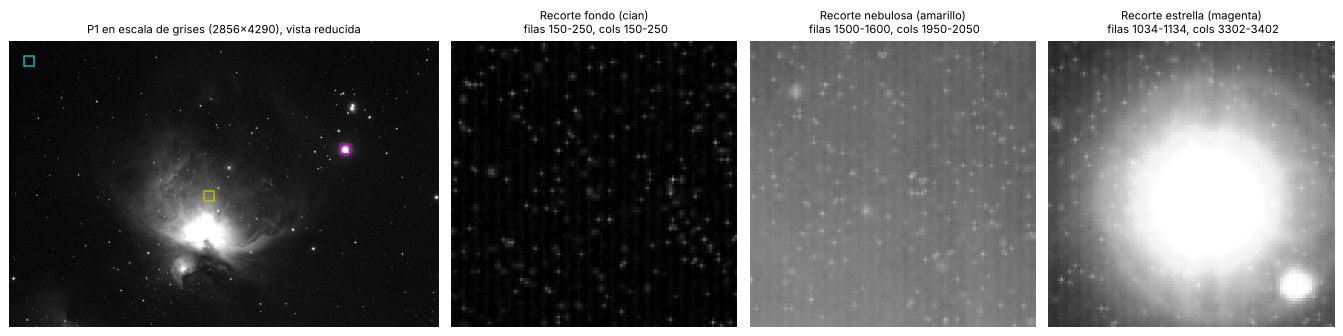

In [3]:
# Recortes usados en toda la pregunta (fila0, col0, tamaño)
REC_FONDO = (150, 150, 100)      # cielo de fondo, casi homogéneo
REC_NEBULOSA = (1500, 1950, 100) # zona de la nebulosa (detalle de interés)
REC_ESTRELLA = (1034, 3302, 100) # estrella brillante (núcleo saturado) para ver ringing


def rec(img, r):
    f, c, s = r
    return img[f:f + s, c:c + s]


fig, ax = plt.subplots(1, 4, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.5, 1, 1, 1]})
ax[0].imshow(estirar(I, LO, HI), cmap="gray", interpolation="antialiased")
for r, colr in [(REC_FONDO, "c"), (REC_NEBULOSA, "y"), (REC_ESTRELLA, "m")]:
    ax[0].add_patch(plt.Rectangle((r[1], r[0]), r[2], r[2], fill=False, ec=colr, lw=1.2))
ax[0].set_title(f"P1 en escala de grises ({M}x{N}), vista reducida")
for a, r, t in zip(ax[1:], [REC_FONDO, REC_NEBULOSA, REC_ESTRELLA], ["fondo (cian)", "nebulosa (amarillo)", "estrella (magenta)"]):
    a.imshow(estirar(rec(I, r), LO, HI), cmap="gray", vmin=0, vmax=1)
    a.set_title(f"Recorte {t}\n filas {r[0]}-{r[0]+r[2]}, cols {r[1]}-{r[1]+r[2]}")
for a in ax:
    a.axis("off")
plt.tight_layout(); guardar(fig, "p1_imagen_original")

## 1.1 Espectro de magnitud e identificación de las componentes periódicas

Se muestra $\log(1+|F(u,v)|)$ centrado. Como el espectro tiene $2856\times4290$ muestras y los
picos del ruido ocupan 1–2 muestras, para la vista completa se reduce por **máximo por bloques**
(así los picos no desaparecen al reducir) y además se amplían ventanas alrededor de cada pico.
Las coordenadas de frecuencia se expresan en **ciclos/píxel** ($f_y, f_x \in [-0.5, 0.5)$).

In [4]:
def coordenadas_frecuencia(forma):
    """Rejillas (FY, FX) en ciclos/píxel, ya centradas (mismo orden que fftshift(F))."""
    fy = sfft.fftshift(sfft.fftfreq(forma[0]))
    fx = sfft.fftshift(sfft.fftfreq(forma[1]))
    return np.meshgrid(fy, fx, indexing="ij")


def espectro_centrado(img):
    return sfft.fftshift(sfft.fft2(img.astype(np.float32), workers=WORKERS))


def reducir_max(a, k):
    m, n = (a.shape[0] // k) * k, (a.shape[1] // k) * k
    return a[:m, :n].reshape(m // k, k, n // k, k).max(axis=(1, 3))


def ventana(F, fy0, fx0, ry=0.012, rx=0.012):
    """Extrae la ventana del espectro centrado alrededor de (fy0, fx0) [ciclos/píxel]."""
    m, n = F.shape
    cy, cx = m // 2 + int(round(fy0 * m)), n // 2 + int(round(fx0 * n))
    hy, hx = int(round(ry * m)), int(round(rx * n))
    filas = np.arange(cy - hy, cy + hy + 1) % m
    cols = np.arange(cx - hx, cx + hx + 1) % n
    return F[np.ix_(filas, cols)], (fx0 - hx / n, fx0 + hx / n, fy0 + hy / m, fy0 - hy / m)


F0 = espectro_centrado(I)
L0 = np.log1p(np.abs(F0))

# Listado de los picos más prominentes (sólo como apoyo para JUSTIFICAR las posiciones; los
# centros de los notch se fijan explícitamente a mano más abajo).
from scipy.ndimage import median_filter
fondo_esp = median_filter(L0, size=9)
prom = L0 - fondo_esp
FY0, FX0 = coordenadas_frecuencia(I.shape)
prom[np.hypot(FY0, FX0) < 0.01] = 0            # se excluye la zona de bajas frecuencias
idx = np.argsort(prom.ravel())[::-1][:12]
print("Picos más prominentes respecto de su vecindad (log-magnitud sobre la mediana local):")
print("   fy [c/px]   fx [c/px]   (fila, col) desde el centro   prominencia")
for i in idx:
    r, c = divmod(i, N)
    print(f"   {FY0[r, c]:+.4f}    {FX0[r, c]:+.4f}     ({r - M // 2:+5d}, {c - N // 2:+5d})            {prom[r, c]:.2f}")
del fondo_esp, prom

Picos más prominentes respecto de su vecindad (log-magnitud sobre la mediana local):
   fy [c/px]   fx [c/px]   (fila, col) desde el centro   prominencia
   +0.0000    +0.2501     (   +0, +1073)            4.63
   +0.0000    -0.2501     (   +0, -1073)            4.63
   +0.0000    -0.2499     (   +0, -1072)            4.63
   +0.0000    +0.2499     (   +0, +1072)            4.63
   -0.5000    -0.2501     (-1428, -1073)            4.53
   -0.5000    -0.2499     (-1428, -1072)            4.48
   -0.5000    +0.2499     (-1428, +1072)            4.40
   -0.5000    +0.2501     (-1428, +1073)            4.40
   +0.0000    -0.2503     (   +0, -1074)            3.59
   +0.0000    +0.2503     (   +0, +1074)            3.59
   +0.0000    -0.2497     (   +0, -1071)            3.58
   +0.0000    +0.2497     (   +0, +1071)            3.58


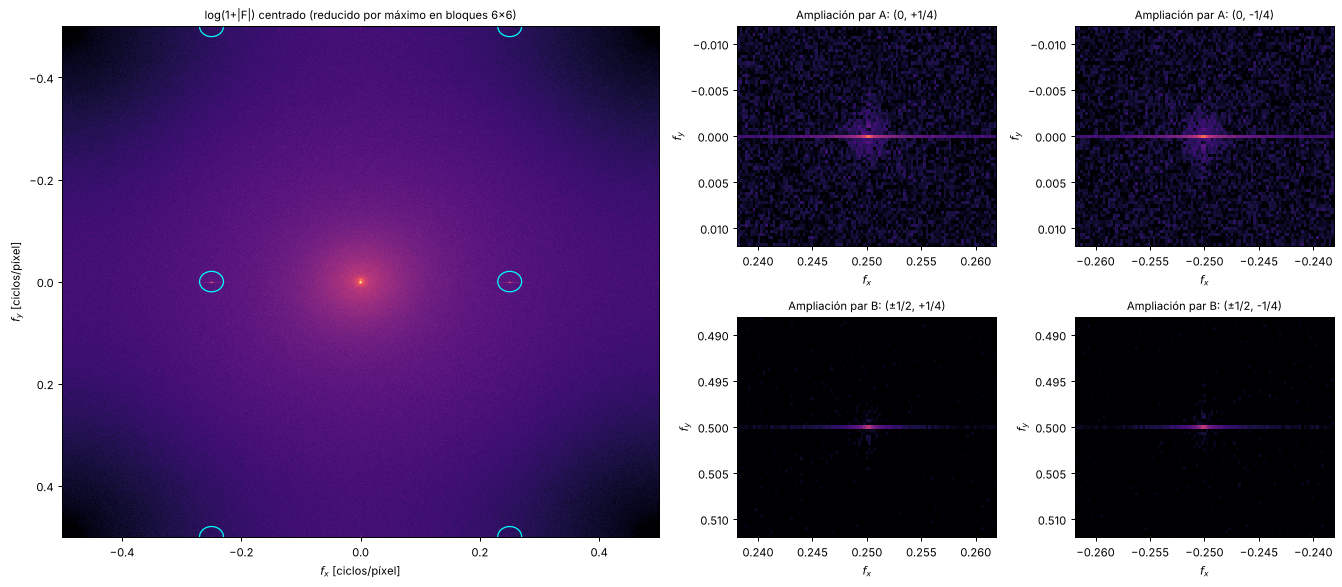

In [5]:
fig = plt.figure(figsize=(15, 6.6))
gs = fig.add_gridspec(2, 4)
a = fig.add_subplot(gs[:, :2])
k = 6
a.imshow(reducir_max(L0, k), cmap="magma", extent=(-0.5, 0.5, 0.5, -0.5), aspect="auto",
         vmin=np.percentile(L0, 5), vmax=L0.max())
for (fy, fx) in [(0, 0.25), (0, -0.25), (0.5, 0.25), (-0.5, -0.25), (0.5, -0.25), (-0.5, 0.25)]:
    a.add_patch(plt.Circle((fx, fy), 0.02, fill=False, ec="cyan", lw=1))
a.set_xlabel("$f_x$ [ciclos/píxel]"); a.set_ylabel("$f_y$ [ciclos/píxel]")
a.set_title(f"log(1+|F|) centrado (reducido por máximo en bloques {k}x{k})")
VMIN_Z, VMAX_Z = np.percentile(L0, 50), L0.max() * 0.93
for j, (fy, fx, t) in enumerate([(0, 0.25, "par A: (0, +1/4)"), (0, -0.25, "par A: (0, -1/4)"),
                                   (0.5, 0.25, "par B: (±1/2, +1/4)"), (0.5, -0.25, "par B: (±1/2, -1/4)")]):
    w, ext = ventana(L0, fy, fx)
    a = fig.add_subplot(gs[j // 2, 2 + j % 2])
    a.imshow(w, cmap="magma", extent=ext, aspect="auto", vmin=VMIN_Z, vmax=VMAX_Z)
    a.set_title("Ampliación " + t); a.set_xlabel("$f_x$"); a.set_ylabel("$f_y$")
plt.tight_layout(); guardar(fig, "p1_espectro")

### Justificación física de las posiciones
El perfil de columnas muestra el origen del ruido: en el RAW, las columnas pares del sensor
(fotositos R y G2) alternan su nivel de offset cada 2 columnas, es decir, con período 4 píxeles,
mientras las columnas impares (G y B) no lo hacen. Una secuencia $[-a, 0, +a, 0]$ repetida es
exactamente $-a\cos(2\pi\, x/4)$: una sinusoide pura de frecuencia $f_x = 1/4$ ciclos/píxel.
Como en las filas pares la componente proviene de R (peso 0.299) y en las impares de G2 (peso
0.587·(1/2) tras el demosaico), la amplitud alterna fila a fila; eso modula la sinusoide por
$(-1)^y$ y genera el **segundo par** en $f_y = \pm 1/2$. Además se verifica que la amplitud y la
fase son constantes a lo largo de toda la imagen (ruido estacionario), por lo que los picos son
muy angostos.

Amplitud global par A: 0.00525 (fase -3.13 rad);  par B: 0.00104
Como referencia, mediana del fondo = 0.0633 -> el patrón es ±8.3 % del fondo


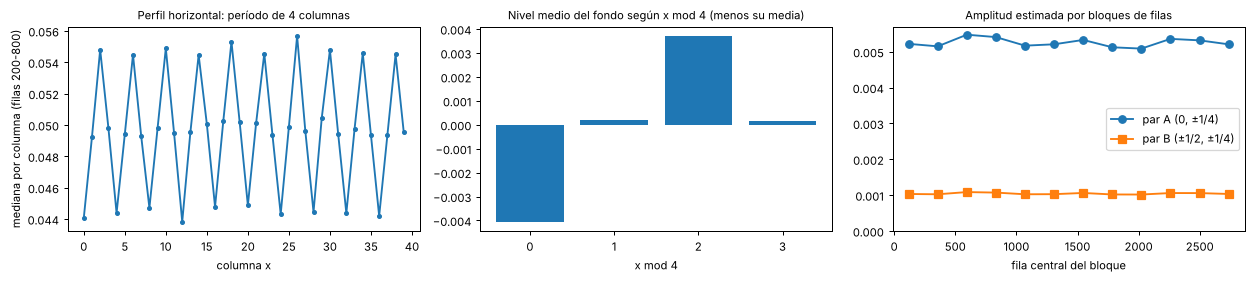

In [6]:
x_col = np.arange(N)
y_fil = np.arange(M)
fondo_mask = I < np.percentile(I, 60)          # píxeles de fondo (sin estrellas ni nebulosa)
Ic = I - np.median(I)


def proyeccion(img, fy, fx):
    """Amplitud compleja de la componente exp(i2π(fy y + fx x)) en la imagen (estimador de
    mínimos cuadrados para una sinusoide real: 2/(MN) * sum img * exp(-i2π(...)))."""
    ey = np.exp(-2j * np.pi * fy * np.arange(img.shape[0]))
    ex = np.exp(-2j * np.pi * fx * np.arange(img.shape[1]))
    return 2.0 * (ey @ img @ ex) / img.size


perf = [np.median(I[:, c::4][fondo_mask[:, c::4]]) for c in range(4)]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].plot(x_col[:40], np.median(I[200:800, :40], axis=0), "o-", ms=3)
ax[0].set_xlabel("columna x"); ax[0].set_ylabel("mediana por columna (filas 200-800)")
ax[0].set_title("Perfil horizontal: período de 4 columnas")
ax[1].bar(range(4), np.array(perf) - np.mean(perf))
ax[1].set_xticks(range(4)); ax[1].set_xlabel("x mod 4")
ax[1].set_title("Nivel medio del fondo según x mod 4 (menos su media)")
bloques = np.array_split(np.arange(M), 12)
amps_A = [np.abs(proyeccion(Ic[b], 0, 0.25)) for b in bloques]
amps_B = [np.abs(proyeccion(Ic[b] * ((-1.0) ** b)[:, None], 0, 0.25)) for b in bloques]
ax[2].plot([b.mean() for b in bloques], amps_A, "o-", label="par A (0, ±1/4)")
ax[2].plot([b.mean() for b in bloques], amps_B, "s-", label="par B (±1/2, ±1/4)")
ax[2].set_ylim(0, None); ax[2].set_xlabel("fila central del bloque"); ax[2].legend()
ax[2].set_title("Amplitud estimada por bloques de filas")
plt.tight_layout(); guardar(fig, "p1_justificacion")
A0 = proyeccion(Ic, 0, 0.25); B0 = proyeccion(Ic, 0.5, 0.25)
print(f"Amplitud global par A: {abs(A0):.5f} (fase {np.angle(A0):+.2f} rad);  par B: {abs(B0):.5f}")
print(f"Como referencia, mediana del fondo = {np.median(I):.4f} -> el patrón es ±{100*abs(A0)/np.median(I):.1f} % del fondo")

**Centros elegidos para los notch** (en ciclos/píxel, configurables):

| Par | Centro $c$ | Simétrico $-c$ |
|---|---|---|
| A | $(0, +0.25)$ | $(0, -0.25)$ |
| B | $(0.5, +0.25)$ | $(-0.5, -0.25) \equiv (0.5, -0.25)$ |

Sólo se declara un centro por par; el simétrico lo agrega automáticamente la función que
construye el filtro. Las distancias se calculan de forma **periódica** (módulo 1 ciclo/píxel),
de modo que el par B, que está justo en la frecuencia de Nyquist vertical, queda bien tratado.

In [7]:
# ======================= CONFIGURACIÓN EXPLÍCITA DE LOS NOTCH =======================
NOTCH_CENTROS = [(0.0, 0.25),   # par A  (fy, fx) en ciclos/píxel
                 (0.5, 0.25)]   # par B
# =====================================================================================

## Implementación: padding, FFT, filtro notch, IFFT y recorte

In [8]:
def distancia_periodica(f, f0):
    """|f - f0| medido en el círculo de frecuencias (período 1 ciclo/píxel)."""
    d = np.abs(f - f0) % 1.0
    return np.minimum(d, 1.0 - d)


def distancia_a_notch(FY, FX, centro):
    """D_k(u,v): distancia euclidiana (en ciclos/píxel) de cada muestra del espectro al centro."""
    return np.hypot(distancia_periodica(FY, centro[0]), distancia_periodica(FX, centro[1]))


def filtro_notch(forma, centros, tipo="gauss", ancho=1e-3):
    """Función de transferencia notch-reject H(u,v), ya CENTRADA (alineada con fftshift(F)).

    centros : lista de (fy, fx) en ciclos/píxel; por cada centro se agrega su simétrico (-fy, -fx).
    tipo    : 'ideal'  -> H = 0 si D <= D0, 1 en otro caso (D0 = ancho)
              'gauss'  -> H = 1 - exp(-D^2 / (2 sigma^2))     (sigma = ancho)
    ancho   : escalar o lista (uno por par), en ciclos/píxel.
    El filtro total es el producto de los filtros de cada notch."""
    FY, FX = coordenadas_frecuencia(forma)
    anchos = np.broadcast_to(np.atleast_1d(ancho), (len(centros),))
    H = np.ones(forma, dtype=np.float32)
    for (fy, fx), a in zip(centros, anchos):
        for s in (+1, -1):                       # el notch y su simétrico
            D = distancia_a_notch(FY, FX, (s * fy, s * fx))
            if tipo == "ideal":
                H *= (D > a)
            elif tipo == "gauss":
                H *= (1.0 - np.exp(-D ** 2 / (2.0 * a ** 2))).astype(np.float32)
            else:
                raise ValueError(tipo)
    return H


def extender(img, pad=0, modo="reflect", multiplo=4):
    """Extiende la imagen. Devuelve (imagen_extendida, (arriba, abajo, izquierda, derecha)).

    modo     : 'none' (sin extensión), 'zeros', 'reflect' (espejo sin repetir el borde),
               'symmetric' (espejo repitiendo el borde) o 'edge' (replica el último valor).
    pad      : píxeles agregados arriba y a la izquierda.
    multiplo : abajo y a la derecha se agrega pad + (lo necesario para que cada dimensión
               extendida sea múltiplo de 'multiplo'). Con multiplo=4 la frecuencia 1/4 cae
               exactamente sobre una muestra de la DFT."""
    if modo == "none":
        return img, (0, 0, 0, 0)
    m, n = img.shape
    t = l = pad
    b = pad + (-(m + 2 * pad)) % multiplo
    r = pad + (-(n + 2 * pad)) % multiplo
    npmodo = {"zeros": "constant", "reflect": "reflect", "symmetric": "symmetric", "edge": "edge"}[modo]
    return np.pad(img, ((t, b), (l, r)), mode=npmodo), (t, b, l, r)


def filtrar_notch(img, centros, tipo="gauss", ancho=1e-3, pad=0, modo="reflect", multiplo=4,
                  devolver_todo=False):
    """Cadena completa: padding -> FFT 2D -> H(u,v) -> F*H (espectro complejo) -> IFFT -> recorte."""
    ext, (t, b, l, r) = extender(img, pad, modo, multiplo)
    F = sfft.fftshift(sfft.fft2(ext.astype(np.float32), workers=WORKERS))   # espectro centrado
    H = filtro_notch(F.shape, centros, tipo, ancho)
    G = F * H                                                              # producto complejo
    g = sfft.ifft2(sfft.ifftshift(G), workers=WORKERS)
    imag_max = float(np.abs(g.imag).max())
    m, n = img.shape
    salida = g.real[t:t + m, l:l + n].astype(np.float64)                   # recorte al tamaño original
    if devolver_todo:
        return salida, dict(F=F, H=H, G=G, ext_shape=ext.shape, bordes=(t, b, l, r), imag_max=imag_max)
    return salida

### Visualización de las funciones de transferencia
Ejemplo de ambas familias alrededor del notch $(0, +1/4)$, con el mismo parámetro de ancho.

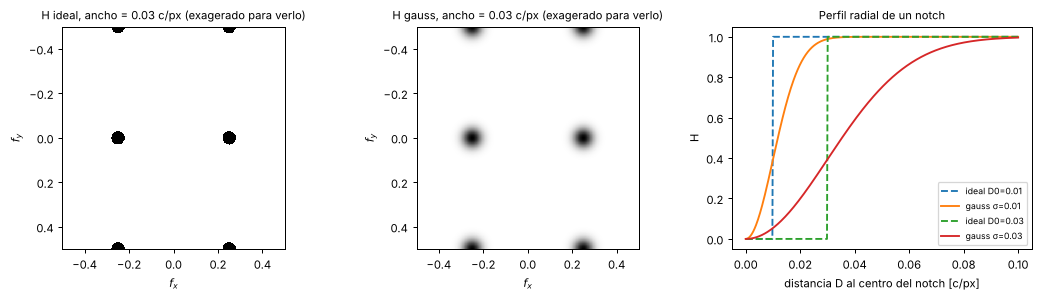

In [9]:
forma_demo = (601, 601)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, tipo in zip(ax[:2], ["ideal", "gauss"]):
    Hd = filtro_notch(forma_demo, NOTCH_CENTROS, tipo, 0.03)
    a.imshow(Hd, cmap="gray", extent=(-0.5, 0.5, 0.5, -0.5), vmin=0, vmax=1)
    a.set_title(f"H {tipo}, ancho = 0.03 c/px (exagerado para verlo)")
    a.set_xlabel("$f_x$"); a.set_ylabel("$f_y$")
d = np.linspace(0, 0.1, 400)
for a0 in [0.01, 0.03]:
    ax[2].plot(d, (d > a0).astype(float), "--", label=f"ideal D0={a0}")
    ax[2].plot(d, 1 - np.exp(-d ** 2 / (2 * a0 ** 2)), label=f"gauss σ={a0}")
ax[2].set_xlabel("distancia D al centro del notch [c/px]"); ax[2].set_ylabel("H"); ax[2].legend(fontsize=7)
ax[2].set_title("Perfil radial de un notch")
plt.tight_layout(); guardar(fig, "p1_filtros")

### Métricas usadas para comparar configuraciones
* **Ruido periódico residual**: amplitud de las componentes A y B que queda en la imagen
  filtrada, en % de la amplitud original. Para que las estrellas y la nebulosa no sesguen la
  estimación, se calcula sobre el **perfil mediano de columnas** (mediana por columna; para el
  par B, mitad de la diferencia entre la mediana de filas pares e impares) proyectado sobre
  $e^{-i2\pi x/4}$.
* **Contenido no periódico eliminado**: RMS de la imagen diferencia (ruidosa − filtrada) después
  de restarle el patrón sinusoidal ajustado. Idealmente el filtro sólo debería quitar el patrón;
  todo lo demás es pérdida de detalle o artefacto (ringing).
* Las mismas métricas se calculan en franjas de 48 px junto a cada borde y en el centro, para
  cuantificar los efectos de borde.

In [10]:
def patron_ajustado(img_dif):
    """Patrón periódico (pares A y B) ajustado por mínimos cuadrados a una imagen."""
    yy = np.arange(img_dif.shape[0])[:, None]; xx = np.arange(img_dif.shape[1])[None, :]
    pat = np.zeros_like(img_dif)
    for fy, fx in NOTCH_CENTROS:
        c = proyeccion(img_dif, fy, fx)
        pat += np.real(c * np.exp(2j * np.pi * (fy * yy + fx * xx)))
    return pat


def amp_robusta(z):
    """Amplitudes (A, B) del patrón de franjas estimadas sobre perfiles medianos de columnas."""
    ex = np.exp(-2j * np.pi * 0.25 * np.arange(z.shape[1]))
    pA = np.median(z, axis=0)
    pB = 0.5 * (np.median(z[0::2], axis=0) - np.median(z[1::2], axis=0))
    return (2 * abs(np.mean((pA - pA.mean()) * ex)), 2 * abs(np.mean((pB - pB.mean()) * ex)))


def metricas(ruidosa, filtrada, zona=None):
    if zona is not None:
        ruidosa, filtrada = ruidosa[zona], filtrada[zona]
    a0, b0 = amp_robusta(ruidosa); a1, b1 = amp_robusta(filtrada)
    resA, resB = 100 * a1 / a0, 100 * b1 / b0
    dif = ruidosa - filtrada
    no_per = np.sqrt(np.mean((dif - patron_ajustado(dif)) ** 2))
    return resA, resB, no_per


ZONAS = {"izq": (slice(None), slice(0, 48)), "der": (slice(None), slice(N - 48, N)),
         "sup": (slice(0, 48), slice(None)), "inf": (slice(M - 48, M), slice(None)),
         "centro": (slice(M // 2 - 300, M // 2 + 300), slice(N // 2 - 400, N // 2 + 400))}

# Patrón periódico "ideal" estimado sobre toda la imagen ruidosa (sinusoides de los pares A y B).
# Sirve de referencia: (ruidosa - filtrada) - PATRON = lo que el filtro quitó de más o de menos.
PATRON = patron_ajustado(I - np.median(I))
print(f"Patrón estimado: amplitud pico = {np.abs(PATRON).max():.4f}")

Patrón estimado: amplitud pico = 0.0063


## 1.3 Estrategia de extensión (padding)

Se estudia primero el padding (ítem 3) porque la estrategia elegida se usa en el barrido de
anchos (ítem 2) y en la configuración final. Se fija un notch Gaussiano angosto
($\sigma = 3\times10^{-4}$ c/px, ~1 muestra de la DFT) y uno ideal con el mismo $D_0$, y se compara:

* **sin padding** ($2856\times4290$; como $4290/4 = 1072.5$, la frecuencia 1/4 cae *entre* dos
  muestras de la DFT y su energía se reparte en muchas muestras — fuga espectral);
* **ceros** con $p = 64$ y $p = 512$ píxeles por lado;
* **reflexión** (espejo sin repetir el borde, `reflect`) con $p = 64$ y $p = 512$;
* **simétrica** (espejo repitiendo el borde) con $p=64$.

En todos los casos con padding, los bordes inferior y derecho reciben píxeles extra para que
el tamaño extendido sea múltiplo de 4 (la frecuencia 1/4 cae exactamente en una muestra).

In [11]:
CONFIG_PAD = [("none", 0), ("zeros", 64), ("zeros", 512), ("reflect", 64), ("reflect", 512), ("symmetric", 64)]
SIGMA_PAD = 3e-4
filas_tabla = []
salidas_pad = {}
for tipo in ["gauss", "ideal"]:
    for modo, p in CONFIG_PAD:
        t0 = time.time()
        out, info = filtrar_notch(I, NOTCH_CENTROS, tipo, SIGMA_PAD, pad=p, modo=modo, devolver_todo=True)
        fila = [tipo, modo, p, info["ext_shape"], info["bordes"]]
        fila += [metricas(I, out)]
        fila += [metricas(I, out, ZONAS[z])[0] for z in ["izq", "der", "sup", "inf", "centro"]]
        filas_tabla.append(fila)
        if tipo == "gauss":
            salidas_pad[(modo, p)] = out
        del info

print(f"Notch con ancho {SIGMA_PAD} c/px. Residual = amplitud del par A remanente (% del original).")
print(f"{'tipo':6s} {'modo':9s} {'p':>4s} {'tamaño ext.':>13s} {'(arr,ab,izq,der)':>20s} | "
      f"{'resA%':>6s} {'resB%':>6s} {'no-per':>8s} | residual A por zona [%]: izq   der   sup   inf  centro")
for f in filas_tabla:
    (rA, rB, npr) = f[5]
    print(f"{f[0]:6s} {f[1]:9s} {f[2]:4d} {str(f[3]):>13s} {str(f[4]):>20s} | {rA:6.2f} {rB:6.2f} {npr:8.2e} | "
          + "  ".join(f"{v:5.1f}" for v in f[6:]))

Notch con ancho 0.0003 c/px. Residual = amplitud del par A remanente (% del original).
tipo   modo         p   tamaño ext.     (arr,ab,izq,der) |  resA%  resB%   no-per | residual A por zona [%]: izq   der   sup   inf  centro
gauss  none         0  (2856, 4290)         (0, 0, 0, 0) |  20.65  20.53 1.04e-03 |  96.3   96.3   21.7   16.8    6.1
gauss  zeros       64  (2984, 4420)     (64, 64, 64, 66) |   7.89   7.52 1.69e-04 |  14.9   14.2   14.7    9.1    6.4
gauss  zeros      512  (3880, 5316) (512, 512, 512, 514) |  21.89  22.62 6.45e-04 |  53.2   53.6   52.2   49.4    6.7
gauss  reflect     64  (2984, 4420)     (64, 64, 64, 66) |   3.94   3.58 1.12e-04 |  10.0    9.1    5.9    1.2    6.1
gauss  reflect    512  (3880, 5316) (512, 512, 512, 514) |  10.72  10.49 5.98e-04 |  27.1   65.0   12.2    6.4    6.1
gauss  symmetric   64  (2984, 4420)     (64, 64, 64, 66) |   4.87  10.96 1.69e-04 |  13.6   14.2    7.8    2.6    6.1
ideal  none         0  (2856, 4290)         (0, 0, 0, 0) |  19.99 

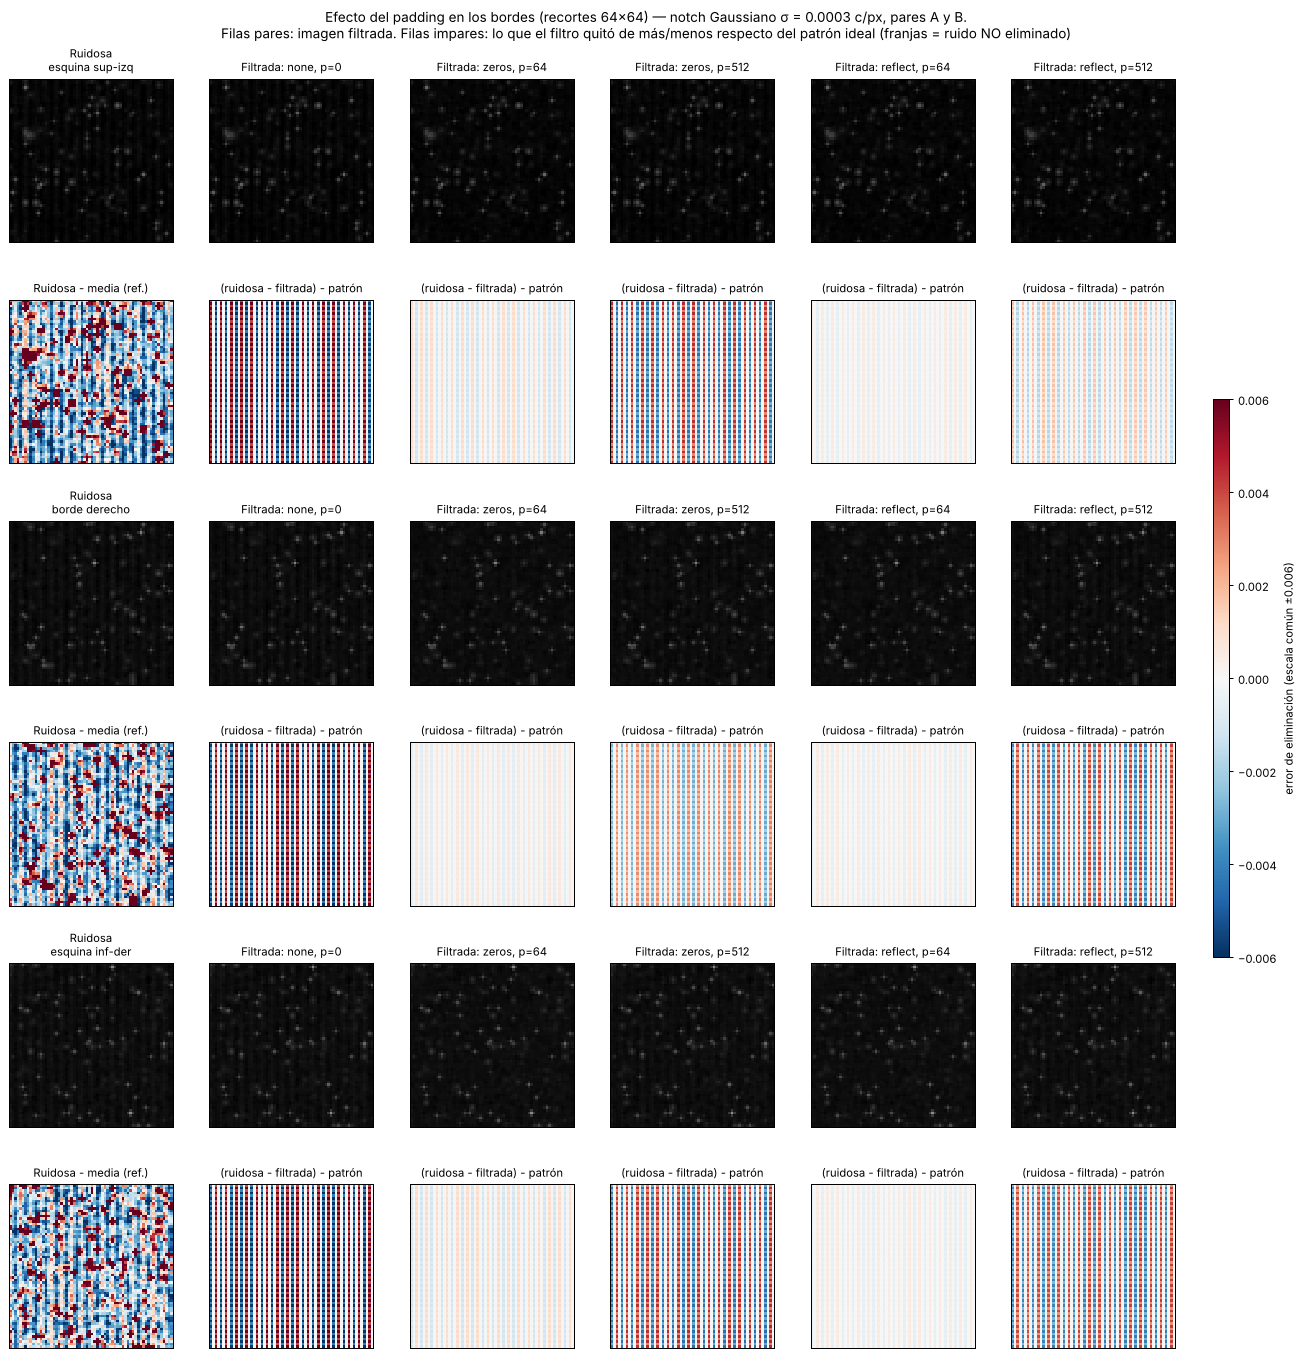

In [12]:
# Recortes ampliados en las esquinas/bordes: imagen filtrada y diferencia (escala común)
bordes_rec = {"esquina sup-izq": (0, 0, 64), "borde derecho": (1400, N - 64, 64), "esquina inf-der": (M - 64, N - 64, 64)}
modos_mostrar = [("none", 0), ("zeros", 64), ("zeros", 512), ("reflect", 64), ("reflect", 512)]
ESC_DIF = 0.012     # escala común para imágenes diferencia (ruidosa - filtrada)
ESC_ERR = 0.006     # escala común para el error de eliminación (diferencia - patrón ideal)
fig, ax = plt.subplots(len(bordes_rec) * 2, len(modos_mostrar) + 1, figsize=(15, 15.5))
fig.subplots_adjust(left=0.02, right=0.9, top=0.93, bottom=0.02, hspace=0.35, wspace=0.08)
for i, (nom, r) in enumerate(bordes_rec.items()):
    ax[2 * i, 0].imshow(estirar(rec(I, r), LO, HI), cmap="gray", vmin=0, vmax=1)
    ax[2 * i, 0].set_title(f"Ruidosa\n{nom}")
    ax[2 * i + 1, 0].imshow(rec(I, r) - rec(I, r).mean(), cmap="RdBu_r", vmin=-ESC_DIF, vmax=ESC_DIF)
    ax[2 * i + 1, 0].set_title("Ruidosa - media (ref.)")
    for j, key in enumerate(modos_mostrar):
        out = salidas_pad[key]
        ax[2 * i, j + 1].imshow(estirar(rec(out, r), LO, HI), cmap="gray", vmin=0, vmax=1)
        ax[2 * i, j + 1].set_title(f"Filtrada: {key[0]}, p={key[1]}")
        im = ax[2 * i + 1, j + 1].imshow(rec(I - out - PATRON, r), cmap="RdBu_r", vmin=-ESC_ERR, vmax=ESC_ERR)
        ax[2 * i + 1, j + 1].set_title("(ruidosa - filtrada) - patrón")
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
cax = fig.add_axes([0.92, 0.3, 0.012, 0.4])
fig.colorbar(im, cax=cax, label=f"error de eliminación (escala común ±{ESC_ERR})")
fig.suptitle(f"Efecto del padding en los bordes (recortes 64x64) — notch Gaussiano σ = {SIGMA_PAD} c/px, pares A y B.\n"
             "Filas pares: imagen filtrada. Filas impares: lo que el filtro quitó de más/menos respecto del patrón ideal "
             "(franjas = ruido NO eliminado)")
guardar(fig, "p1_padding_bordes")

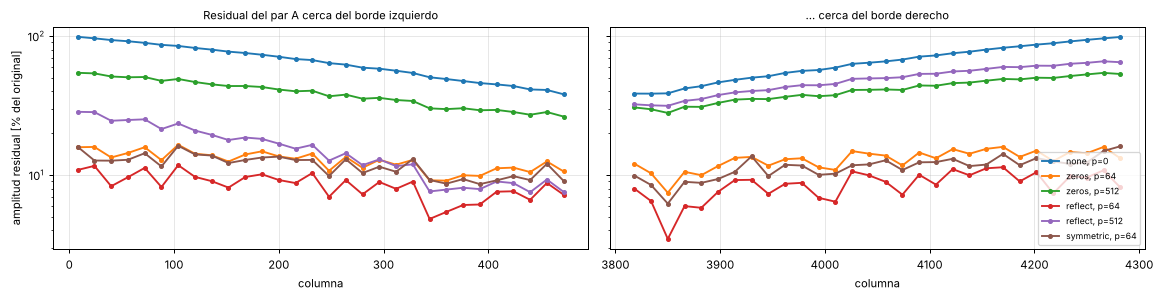

In [13]:
# Perfil del residual periódico cerca del borde izquierdo y derecho (amplitud del par A por
# columnas, estimada en bloques de 16 columnas)
def amp_por_columnas(img, c0, c1, paso=16):
    xs, amps = [], []
    for c in range(c0, c1, paso):
        amps.append(amp_robusta(img[:, c:c + paso])[0])
        xs.append(c + paso / 2)
    return np.array(xs), np.array(amps)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for key in modos_mostrar + [("symmetric", 64)]:
    for a, (c0, c1) in zip(ax, [(0, 480), (N - 480, N)]):
        xs, am = amp_por_columnas(salidas_pad[key], c0, c1)
        _, am0 = amp_por_columnas(I, c0, c1)
        a.plot(xs, am / am0 * 100, "o-", ms=3, label=f"{key[0]}, p={key[1]}")
ax[0].set_title("Residual del par A cerca del borde izquierdo"); ax[1].set_title("... cerca del borde derecho")
ax[0].set_ylabel("amplitud residual [% del original]")
for a in ax:
    a.set_xlabel("columna"); a.set_yscale("log"); a.grid(alpha=0.3)
ax[1].legend(fontsize=7)
plt.tight_layout(); guardar(fig, "p1_padding_perfil")

**Estrategia seleccionada:** reflexión (`reflect`) con $p = 64$ píxeles por lado y alineación
del tamaño a múltiplo de 4 (ver justificación en el informe y en la tabla anterior). Se usa en
todo el resto de la pregunta.

In [14]:
PAD_MODO, PAD_P, PAD_MULT = "reflect", 64, 4
ext_demo, bordes_demo = extender(I, PAD_P, PAD_MODO, PAD_MULT)
print(f"Padding elegido: modo='{PAD_MODO}', p={PAD_P}. Tamaño {I.shape} -> {ext_demo.shape}; "
      f"(arriba, abajo, izquierda, derecha) = {bordes_demo}")
print("Recorte posterior: salida = g[arriba:arriba+M, izquierda:izquierda+N]")
del ext_demo

Padding elegido: modo='reflect', p=64. Tamaño (2856, 4290) -> (2984, 4420); (arriba, abajo, izquierda, derecha) = (64, 64, 64, 66)
Recorte posterior: salida = g[arriba:arriba+M, izquierda:izquierda+N]


## 1.2 Barrido sistemático del ancho de los notch (ideal y Gaussiano)

In [15]:
ANCHOS = [3e-4, 1e-3, 3e-3, 1e-2, 3e-2]
res_anchos = {}
tabla_anchos = []
for tipo in ["ideal", "gauss"]:
    for a in ANCHOS:
        out = filtrar_notch(I, NOTCH_CENTROS, tipo, a, PAD_P, PAD_MODO, PAD_MULT)
        res_anchos[(tipo, a)] = out
        rA, rB, npr = metricas(I, out)
        npr_est = metricas(I, out, (slice(REC_ESTRELLA[0], REC_ESTRELLA[0] + REC_ESTRELLA[2]),
                                    slice(REC_ESTRELLA[1], REC_ESTRELLA[1] + REC_ESTRELLA[2])))[2]
        tabla_anchos.append((tipo, a, rA, rB, npr, npr_est))
print(f"Padding: {PAD_MODO}, p={PAD_P}.  'no-per' = RMS de lo eliminado que NO es el patrón periódico")
print(f"{'tipo':6s} {'ancho[c/px]':>11s} {'~muestras x':>11s} | {'resA %':>7s} {'resB %':>7s} | {'no-per (total)':>14s} {'no-per (estrella)':>17s}")
for t in tabla_anchos:
    print(f"{t[0]:6s} {t[1]:11.0e} {t[1]*N:11.1f} | {t[2]:7.2f} {t[3]:7.2f} | {t[4]:14.2e} {t[5]:17.2e}")

Padding: reflect, p=64.  'no-per' = RMS de lo eliminado que NO es el patrón periódico
tipo   ancho[c/px] ~muestras x |  resA %  resB % | no-per (total) no-per (estrella)
ideal        3e-04         1.3 |    4.07    3.67 |       1.25e-04          7.34e-06
ideal        1e-03         4.3 |    2.57    2.13 |       3.16e-04          4.34e-05
ideal        3e-03        12.9 |    2.05    1.61 |       4.85e-04          1.44e-04
ideal        1e-02        42.9 |    1.27    0.85 |       6.47e-04          6.22e-04
ideal        3e-02       128.7 |    1.01    0.75 |       1.60e-03          2.11e-03
gauss        3e-04         1.3 |    3.94    3.58 |       1.12e-04          6.50e-06
gauss        1e-03         4.3 |    2.83    2.46 |       2.67e-04          1.88e-05
gauss        3e-03        12.9 |    1.89    1.45 |       3.85e-04          7.98e-05
gauss        1e-02        42.9 |    1.29    0.96 |       6.28e-04          8.37e-04
gauss        3e-02       128.7 |    1.05    0.61 |       1.61e-03         

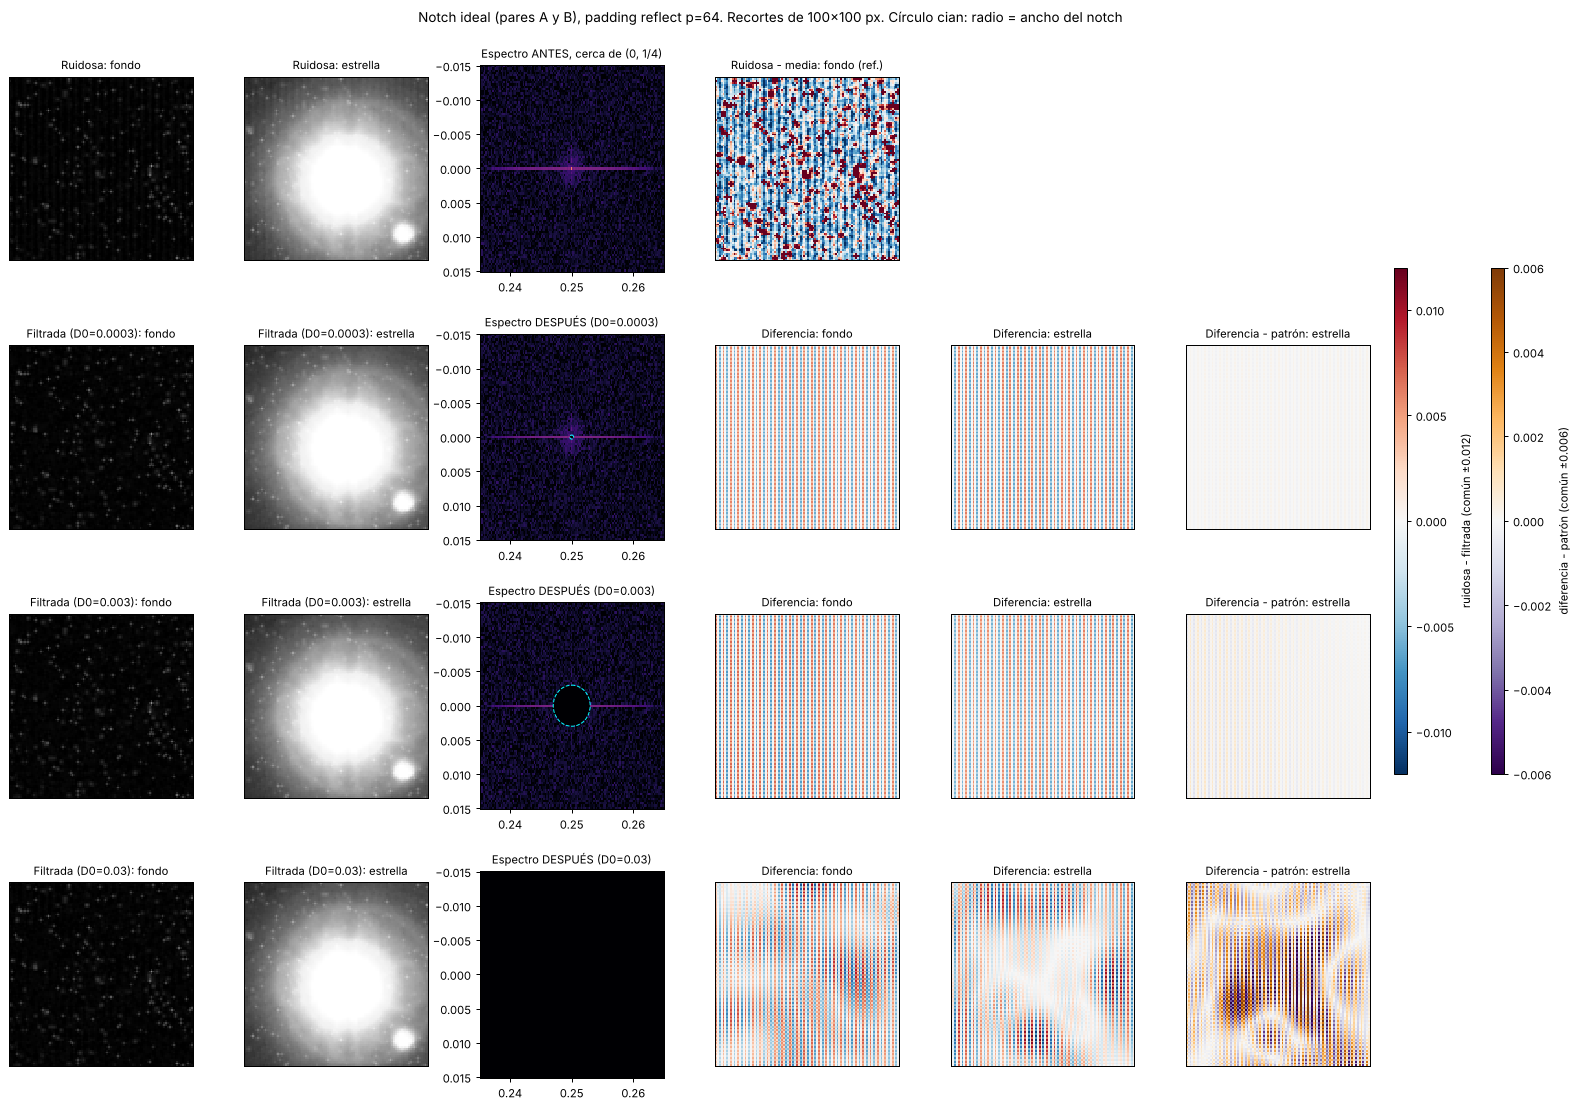

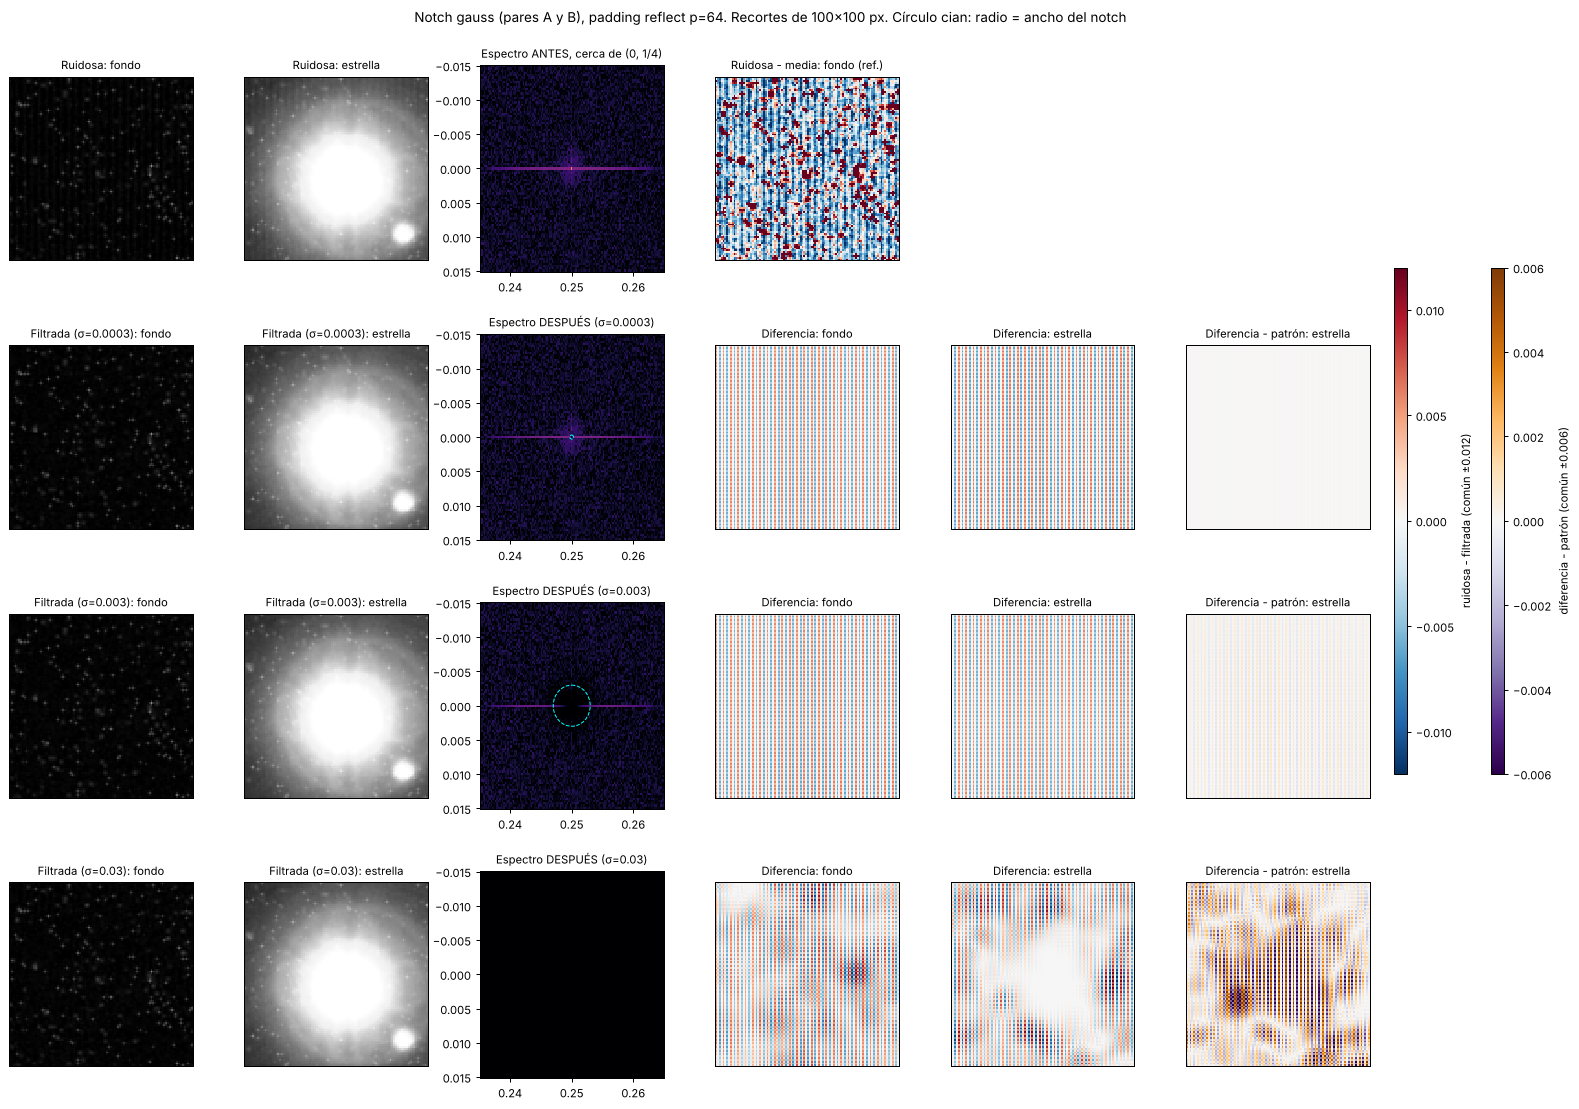

In [16]:
# Figura principal del barrido: para cada familia, 3 anchos representativos
ANCHOS_FIG = [3e-4, 3e-3, 3e-2]
RZ = 0.015   # semiancho de la ventana espectral mostrada [c/px]
_, info_pad = filtrar_notch(I, NOTCH_CENTROS, "gauss", 3e-4, PAD_P, PAD_MODO, PAD_MULT, devolver_todo=True)
Lpad = np.log1p(np.abs(info_pad["F"]))
VMIN_Z, VMAX_Z = np.percentile(Lpad, 50), Lpad.max() * 0.93
del info_pad
for tipo in ["ideal", "gauss"]:
    fig, ax = plt.subplots(len(ANCHOS_FIG) + 1, 6, figsize=(18, 12.5))
    fig.subplots_adjust(left=0.03, right=0.87, top=0.93, bottom=0.03, hspace=0.3, wspace=0.28)
    w, ext = ventana(Lpad, 0, 0.25, RZ, RZ)
    ax[0, 0].imshow(estirar(rec(I, REC_FONDO), LO, HI), cmap="gray", vmin=0, vmax=1); ax[0, 0].set_title("Ruidosa: fondo")
    ax[0, 1].imshow(estirar(rec(I, REC_ESTRELLA), LO, HI), cmap="gray", vmin=0, vmax=1); ax[0, 1].set_title("Ruidosa: estrella")
    ax[0, 2].imshow(w, cmap="magma", extent=ext, aspect="auto", vmin=VMIN_Z, vmax=VMAX_Z); ax[0, 2].set_title("Espectro ANTES, cerca de (0, 1/4)")
    ax[0, 3].imshow(rec(I, REC_FONDO) - rec(I, REC_FONDO).mean(), cmap="RdBu_r", vmin=-ESC_DIF, vmax=ESC_DIF)
    ax[0, 3].set_title("Ruidosa - media: fondo (ref.)")
    ax[0, 4].axis("off"); ax[0, 5].axis("off")
    for i, a0 in enumerate(ANCHOS_FIG, start=1):
        out, info = filtrar_notch(I, NOTCH_CENTROS, tipo, a0, PAD_P, PAD_MODO, PAD_MULT, devolver_todo=True)
        LG = np.log1p(np.abs(info["G"]))
        w, ext = ventana(LG, 0, 0.25, RZ, RZ)
        del info, LG
        etiqueta = f"{'D0' if tipo == 'ideal' else 'σ'}={a0:g}"
        ax[i, 0].imshow(estirar(rec(out, REC_FONDO), LO, HI), cmap="gray", vmin=0, vmax=1); ax[i, 0].set_title(f"Filtrada ({etiqueta}): fondo")
        ax[i, 1].imshow(estirar(rec(out, REC_ESTRELLA), LO, HI), cmap="gray", vmin=0, vmax=1); ax[i, 1].set_title(f"Filtrada ({etiqueta}): estrella")
        ax[i, 2].imshow(w, cmap="magma", extent=ext, aspect="auto", vmin=VMIN_Z, vmax=VMAX_Z); ax[i, 2].set_title(f"Espectro DESPUÉS ({etiqueta})")
        ax[i, 2].add_patch(plt.Circle((0.25, 0), a0, fill=False, ec="cyan", lw=0.8, ls="--"))
        ax[i, 2].set_xlim(ext[0], ext[1]); ax[i, 2].set_ylim(ext[2], ext[3])
        ax[i, 3].imshow(rec(I - out, REC_FONDO), cmap="RdBu_r", vmin=-ESC_DIF, vmax=ESC_DIF); ax[i, 3].set_title(f"Diferencia: fondo")
        im = ax[i, 4].imshow(rec(I - out, REC_ESTRELLA), cmap="RdBu_r", vmin=-ESC_DIF, vmax=ESC_DIF); ax[i, 4].set_title(f"Diferencia: estrella")
        im2 = ax[i, 5].imshow(rec(I - out - PATRON, REC_ESTRELLA), cmap="PuOr_r", vmin=-ESC_ERR, vmax=ESC_ERR)
        ax[i, 5].set_title("Diferencia - patrón: estrella")
    for a in ax.ravel():
        if a not in ax[:, 2]:
            a.set_xticks([]); a.set_yticks([])
    fig.colorbar(im, cax=fig.add_axes([0.885, 0.3, 0.008, 0.45]), label=f"ruidosa - filtrada (común ±{ESC_DIF})")
    fig.colorbar(im2, cax=fig.add_axes([0.945, 0.3, 0.008, 0.45]), label=f"diferencia - patrón (común ±{ESC_ERR})")
    fig.suptitle(f"Notch {tipo} (pares A y B), padding {PAD_MODO} p={PAD_P}. Recortes de 100x100 px. "
                 f"Círculo cian: radio = ancho del notch", y=0.98)
    guardar(fig, f"p1_barrido_{tipo}")
del Lpad

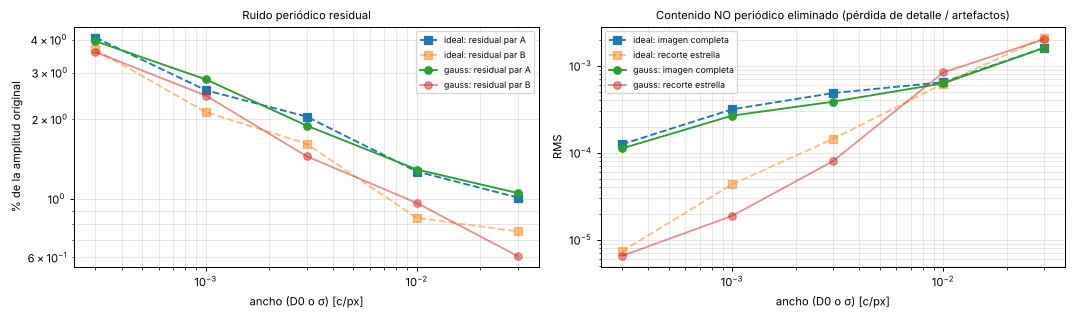

In [17]:
# Resumen cuantitativo del barrido
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for tipo, mk in [("ideal", "s--"), ("gauss", "o-")]:
    T = [t for t in tabla_anchos if t[0] == tipo]
    ax[0].loglog([t[1] for t in T], [max(t[2], 1e-3) for t in T], mk, label=f"{tipo}: residual par A")
    ax[0].loglog([t[1] for t in T], [max(t[3], 1e-3) for t in T], mk, alpha=0.5, label=f"{tipo}: residual par B")
    ax[1].loglog([t[1] for t in T], [t[4] for t in T], mk, label=f"{tipo}: imagen completa")
    ax[1].loglog([t[1] for t in T], [t[5] for t in T], mk, alpha=0.5, label=f"{tipo}: recorte estrella")
ax[0].set_xlabel("ancho (D0 o σ) [c/px]"); ax[0].set_ylabel("% de la amplitud original"); ax[0].legend(fontsize=7)
ax[0].set_title("Ruido periódico residual")
ax[1].set_xlabel("ancho (D0 o σ) [c/px]"); ax[1].set_ylabel("RMS"); ax[1].legend(fontsize=7)
ax[1].set_title("Contenido NO periódico eliminado (pérdida de detalle / artefactos)")
for a in ax:
    a.grid(alpha=0.3, which="both")
plt.tight_layout(); guardar(fig, "p1_barrido_metricas")

## 1.4 Configuración final seleccionada

Configuración final: notch gauss, σ = 0.001 c/px, centros [(0.0, 0.25), (0.5, 0.25)] (+ simétricos),
padding reflect p=64 (múltiplo 4); tamaño extendido (2984, 4420)
Residual par A = 2.83 %, par B = 2.46 %, contenido no periódico eliminado (RMS) = 2.67e-04
max |Im(ifft)| = 2.76e-07  (≈0: el filtro conserva la simetría hermitiana)
Píxeles saturados (I >= 0.999): 0.13 %. En ellos no existía el patrón (recortado por el sensor);
tras el filtrado su desviación estándar pasa de 7.8e-05 a 4.5e-03 (el filtro 'imprime' el patrón invertido en los núcleos saturados).


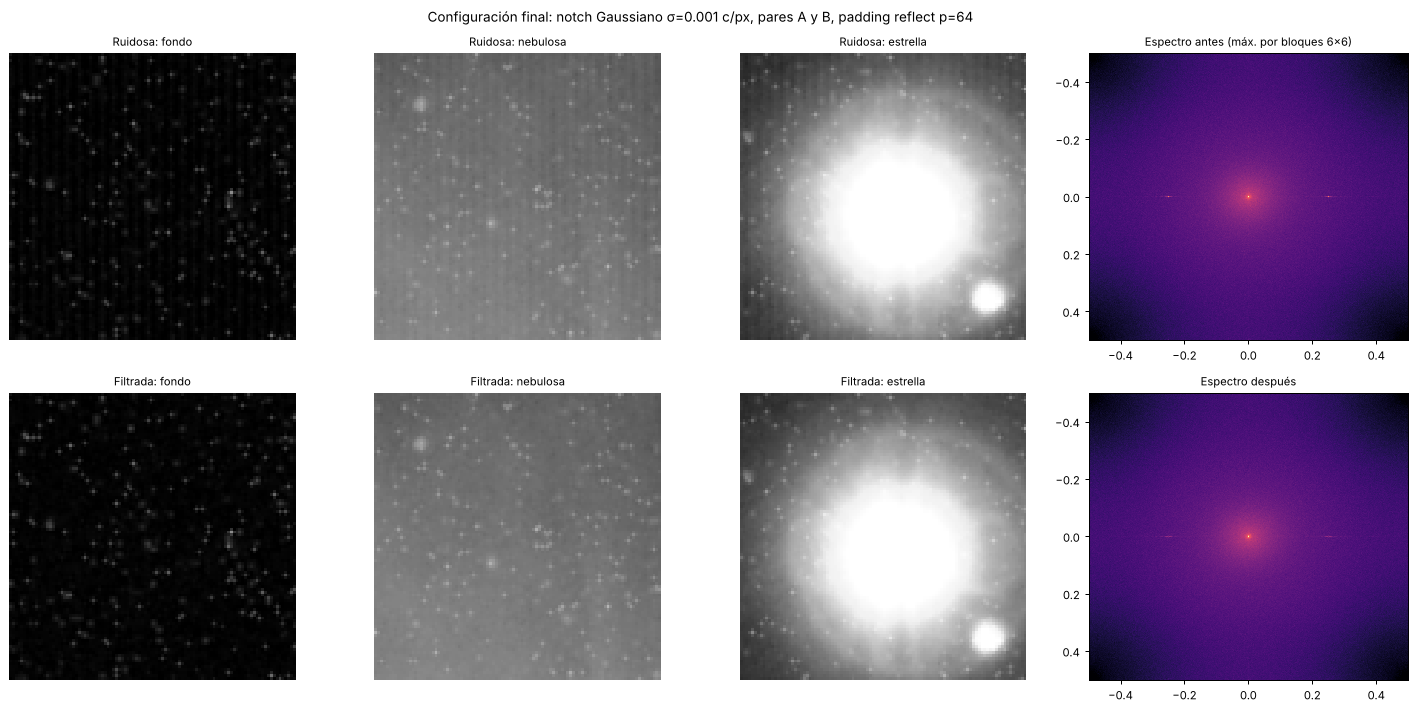

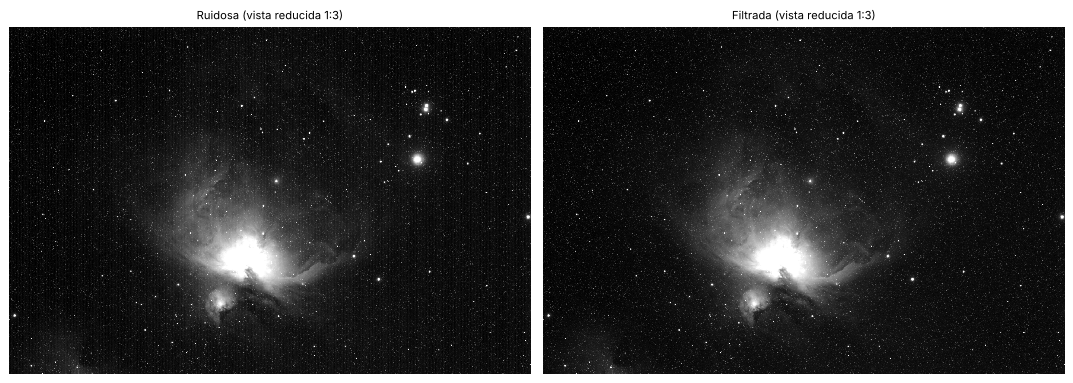

In [18]:
TIPO_FINAL, ANCHO_FINAL = "gauss", 1e-3
I_filt, info_final = filtrar_notch(I, NOTCH_CENTROS, TIPO_FINAL, ANCHO_FINAL, PAD_P, PAD_MODO, PAD_MULT,
                                   devolver_todo=True)
rA, rB, npr = metricas(I, I_filt)
print(f"Configuración final: notch {TIPO_FINAL}, σ = {ANCHO_FINAL} c/px, centros {NOTCH_CENTROS} (+ simétricos),")
print(f"padding {PAD_MODO} p={PAD_P} (múltiplo {PAD_MULT}); tamaño extendido {info_final['ext_shape']}")
print(f"Residual par A = {rA:.2f} %, par B = {rB:.2f} %, contenido no periódico eliminado (RMS) = {npr:.2e}")
print(f"max |Im(ifft)| = {info_final['imag_max']:.2e}  (≈0: el filtro conserva la simetría hermitiana)")
np.save(RES / "P1_filtrada.npy", I_filt.astype(np.float32))
sat = I >= 0.999
print(f"Píxeles saturados (I >= 0.999): {100*sat.mean():.2f} %. En ellos no existía el patrón (recortado por el sensor);")
print(f"tras el filtrado su desviación estándar pasa de {I[sat].std():.1e} a {I_filt[sat].std():.1e} "
      f"(el filtro 'imprime' el patrón invertido en los núcleos saturados).")

fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for j, (r, t) in enumerate([(REC_FONDO, "fondo"), (REC_NEBULOSA, "nebulosa"), (REC_ESTRELLA, "estrella")]):
    ax[0, j].imshow(estirar(rec(I, r), LO, HI), cmap="gray", vmin=0, vmax=1); ax[0, j].set_title(f"Ruidosa: {t}")
    ax[1, j].imshow(estirar(rec(I_filt, r), LO, HI), cmap="gray", vmin=0, vmax=1); ax[1, j].set_title(f"Filtrada: {t}")
Lf = np.log1p(np.abs(info_final["F"])); Lg = np.log1p(np.abs(info_final["G"]))
ax[0, 3].imshow(reducir_max(Lf, 6), cmap="magma", extent=(-0.5, 0.5, 0.5, -0.5), aspect="auto", vmin=np.percentile(Lf, 5), vmax=Lf.max())
ax[0, 3].set_title("Espectro antes (máx. por bloques 6x6)")
ax[1, 3].imshow(reducir_max(Lg, 6), cmap="magma", extent=(-0.5, 0.5, 0.5, -0.5), aspect="auto", vmin=np.percentile(Lf, 5), vmax=Lf.max())
ax[1, 3].set_title("Espectro después")
for a in ax[:, :3].ravel():
    a.axis("off")
fig.suptitle(f"Configuración final: notch Gaussiano σ={ANCHO_FINAL} c/px, pares A y B, padding reflect p={PAD_P}")
plt.tight_layout(); guardar(fig, "p1_final")
del Lf, Lg

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].imshow(estirar(I, LO, HI)[::3, ::3], cmap="gray"); ax[0].set_title("Ruidosa (vista reducida 1:3)")
ax[1].imshow(estirar(I_filt, LO, HI)[::3, ::3], cmap="gray"); ax[1].set_title("Filtrada (vista reducida 1:3)")
for a in ax: a.axis("off")
plt.tight_layout(); guardar(fig, "p1_final_completa")

## Preguntas guiadas: valores numéricos
### Valor complejo del espectro antes y después en una frecuencia afectada por un notch
Se toma la muestra del espectro extendido ubicada **una muestra a la derecha** del centro del
notch $(0, +1/4)$ (en el centro exacto $H=0$ y el resultado es trivial).

In [19]:
F_ext, H_ext, G_ext = info_final["F"], info_final["H"], info_final["G"]
Mp, Np = F_ext.shape
FYp, FXp = coordenadas_frecuencia((Mp, Np))
fila_c, col_c = Mp // 2, Np // 2 + Np // 4           # muestra (0, +1/4) en el espectro centrado
for dc in [0, 1, 3]:
    fF, hH, gG = F_ext[fila_c, col_c + dc], H_ext[fila_c, col_c + dc], G_ext[fila_c, col_c + dc]
    print(f"(fila {fila_c}, col {col_c + dc}) -> (fy, fx) = ({FYp[fila_c, col_c + dc]:+.6f}, {FXp[fila_c, col_c + dc]:+.6f}) c/px")
    print(f"   F = {fF.real:+.4e} {fF.imag:+.4e}j   |F| = {abs(fF):.4e}, fase = {np.angle(fF):+.3f} rad")
    print(f"   H = {hH:.6f}")
    print(f"   G = F·H = {gG.real:+.4e} {gG.imag:+.4e}j   |G| = {abs(gG):.4e}, fase = {np.angle(gG):+.3f} rad")
# simétrico
fila_s, col_s = (Mp - fila_c) % Mp, (Np - (col_c + 1)) % Np
print(f"Muestra simétrica (fila {fila_s}, col {col_s}): F = {F_ext[fila_s, col_s]:.4e}  (conjugado del anterior: "
      f"{np.conj(F_ext[fila_c, col_c + 1]):.4e}),  H = {H_ext[fila_s, col_s]:.6f}")

(fila 1492, col 3315) -> (fy, fx) = (+0.000000, +0.250000) c/px
   F = -3.3609e+04 -2.9663e+02j   |F| = 3.3611e+04, fase = -3.133 rad
   H = 0.000000
   G = F·H = +0.0000e+00 -0.0000e+00j   |G| = 0.0000e+00, fase = -0.000 rad
(fila 1492, col 3316) -> (fy, fx) = (+0.000000, +0.250226) c/px
   F = +8.5290e+02 -5.1315e+01j   |F| = 8.5445e+02, fase = -0.060 rad
   H = 0.025269
   G = F·H = +2.1552e+01 -1.2966e+00j   |G| = 2.1591e+01, fase = -0.060 rad
(fila 1492, col 3318) -> (fy, fx) = (+0.000000, +0.250679) c/px
   F = +9.2668e+02 -1.5873e+01j   |F| = 9.2682e+02, fase = -0.017 rad
   H = 0.205736
   G = F·H = +1.9065e+02 -3.2657e+00j   |G| = 1.9068e+02, fase = -0.017 rad
Muestra simétrica (fila 1492, col 1104): F = 8.5290e+02+5.1315e+01j  (conjugado del anterior: 8.5290e+02+5.1315e+01j),  H = 0.025269


### ¿Qué ocurre si se elimina sólo uno de los dos notches de un par?
Se construye una máscara que anula sólo $(0, +1/4)$ y $(0.5, +1/4)$ (sin sus simétricos).

max |Im(g)| con un solo notch por par: 3.307e-03   (con el par completo: 2.8e-07)
Residual del par A en Re(g): 51.1 %  -> sólo se elimina la mitad de la sinusoide


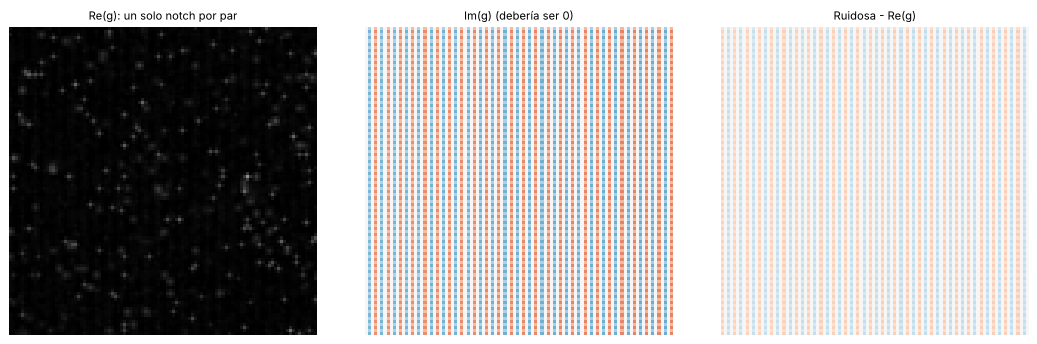

In [20]:
def filtro_notch_sin_simetrico(forma, centros, ancho):
    FY, FX = coordenadas_frecuencia(forma)
    H = np.ones(forma, dtype=np.float32)
    for c in centros:
        D = distancia_a_notch(FY, FX, c)
        H *= (1.0 - np.exp(-D ** 2 / (2.0 * ancho ** 2))).astype(np.float32)
    return H

ext, (t, b, l, r) = extender(I, PAD_P, PAD_MODO, PAD_MULT)
F = sfft.fftshift(sfft.fft2(ext.astype(np.float32), workers=WORKERS))
H1 = filtro_notch_sin_simetrico(F.shape, NOTCH_CENTROS, ANCHO_FINAL)
g1 = sfft.ifft2(sfft.ifftshift(F * H1), workers=WORKERS)[t:t + M, l:l + N]
del F, H1, ext
print(f"max |Im(g)| con un solo notch por par: {np.abs(g1.imag).max():.3e}   (con el par completo: {info_final['imag_max']:.1e})")
rA1 = abs(proyeccion(g1.real - np.median(g1.real), 0, 0.25)) / abs(A0) * 100
print(f"Residual del par A en Re(g): {rA1:.1f} %  -> sólo se elimina la mitad de la sinusoide")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
ax[0].imshow(estirar(rec(g1.real, REC_FONDO), LO, HI), cmap="gray", vmin=0, vmax=1); ax[0].set_title("Re(g): un solo notch por par")
ax[1].imshow(rec(g1.imag, REC_FONDO), cmap="RdBu_r", vmin=-ESC_DIF / 2, vmax=ESC_DIF / 2); ax[1].set_title("Im(g) (debería ser 0)")
ax[2].imshow(rec(I - g1.real, REC_FONDO), cmap="RdBu_r", vmin=-ESC_DIF, vmax=ESC_DIF); ax[2].set_title("Ruidosa - Re(g)")
for a in ax: a.axis("off")
plt.tight_layout(); guardar(fig, "p1_un_notch")
del g1, info_final, F_ext, H_ext, G_ext

## Bonus — Selección adaptativa del ancho del notch

Objetivo: elegir $\sigma$ (notch Gaussiano, pares A y B) minimizando la **varianza local media**
en regiones aproximadamente homogéneas del cielo. La varianza local se calcula con ventanas de
$w\times w$ ($w=5$) mediante promedios locales: $\mathrm{var}_{loc} = \overline{I^2} - \bar I^2$.
Para que las estrellas no dominen la varianza, en cada región se excluyen los píxeles cuya
ventana contiene una estrella (máscara construida sobre la imagen ruidosa por umbral robusto).

Para no recalcular la FFT en cada evaluación, el espectro extendido se calcula una sola vez y
sólo se cambia $H$ (la búsqueda es por grilla logarítmica; no se usan optimizadores externos).

In [21]:
REGIONES_HOMOG = [(100, 100, 300), (2450, 3800, 300), (300, 2700, 300)]   # (fila, col, tamaño)
W_LOC = 5

def mascara_sin_estrellas(img, r):
    z = rec(img, r)
    med = np.median(z); mad = 1.4826 * np.median(np.abs(z - med))
    estrella = z > med + 4 * mad
    return uniform_filter(estrella.astype(float), 2 * W_LOC + 1) == 0

MASCARAS = [mascara_sin_estrellas(I, r) for r in REGIONES_HOMOG]

def varianza_local_media(img):
    vals = []
    for r, mk in zip(REGIONES_HOMOG, MASCARAS):
        z = rec(img, r)
        m1 = uniform_filter(z, W_LOC); m2 = uniform_filter(z * z, W_LOC)
        vals.append(np.mean((m2 - m1 ** 2)[mk]))
    return float(np.mean(vals))

ext, (t, b, l, r_) = extender(I, PAD_P, PAD_MODO, PAD_MULT)
F_ext = sfft.fftshift(sfft.fft2(ext.astype(np.float32), workers=WORKERS))
del ext

def evaluar(sigma):
    H = filtro_notch(F_ext.shape, NOTCH_CENTROS, "gauss", sigma)
    g = sfft.ifft2(sfft.ifftshift(F_ext * H), workers=WORKERS).real[t:t + M, l:l + N]
    E_quit = float(np.sum((1 - H.astype(np.float64)) ** 2 * np.abs(F_ext) ** 2) / np.sum(np.abs(F_ext) ** 2))
    return g, varianza_local_media(g), E_quit

SIGMAS = np.logspace(-4.5, -0.9, 25)
v0 = varianza_local_media(I)
J, Equit, npers = [], [], []
for s in SIGMAS:
    g, v, e = evaluar(s)
    J.append(v); Equit.append(e); npers.append(metricas(I, g)[2])
J, Equit, npers = map(np.array, (J, Equit, npers))
s_min = SIGMAS[np.argmin(J)]
# Criterio adicional (restricción simple): la energía espectral eliminada no puede superar en
# más de un 5 % a la energía del patrón periódico, estimada como la energía que quita el notch
# más angosto de la grilla. Se minimiza J sólo entre los sigma que cumplen la restricción.
E_ref = Equit[0]
factible = Equit <= 1.05 * E_ref
s_res = SIGMAS[factible][np.argmin(J[factible])]
print(f"Varianza local media sin filtrar: {v0:.4e}")
print(f"Mínimo sin restricción:  σ* = {s_min:.2e} c/px  (J = {J.min():.4e}, energía eliminada = {100*Equit[np.argmin(J)]:.3f} %)")
print(f"Mínimo con restricción (E_eliminada <= 1.05·E_patrón = {105*E_ref:.4f} %): σ = {s_res:.2e} c/px "
      f"(J = {J[SIGMAS == s_res][0]:.5e})")
for s, j, e, n_ in zip(SIGMAS, J, Equit, npers):
    print(f"   σ = {s:.2e}   J = {j:.5e}   energía espectral eliminada = {100*e:.4f} %   no-per = {n_:.2e}")

Varianza local media sin filtrar: 2.8613e-05
Mínimo sin restricción:  σ* = 1.26e-01 c/px  (J = 6.6094e-06, energía eliminada = 7.045 %)
Mínimo con restricción (E_eliminada <= 1.05·E_patrón = 0.0819 %): σ = 2.00e-03 c/px (J = 1.48479e-05)
   σ = 3.16e-05   J = 1.48769e-05   energía espectral eliminada = 0.0780 %   no-per = 4.65e-08
   σ = 4.47e-05   J = 1.48769e-05   energía espectral eliminada = 0.0780 %   no-per = 4.65e-08
   σ = 6.31e-05   J = 1.48770e-05   energía espectral eliminada = 0.0780 %   no-per = 2.07e-07
   σ = 8.91e-05   J = 1.48770e-05   energía espectral eliminada = 0.0780 %   no-per = 4.98e-06
   σ = 1.26e-04   J = 1.48781e-05   energía espectral eliminada = 0.0780 %   no-per = 2.48e-05
   σ = 1.78e-04   J = 1.48827e-05   energía espectral eliminada = 0.0780 %   no-per = 5.61e-05
   σ = 2.51e-04   J = 1.48932e-05   energía espectral eliminada = 0.0781 %   no-per = 9.11e-05
   σ = 3.55e-04   J = 1.49100e-05   energía espectral eliminada = 0.0781 %   no-per = 1.33e-04
  

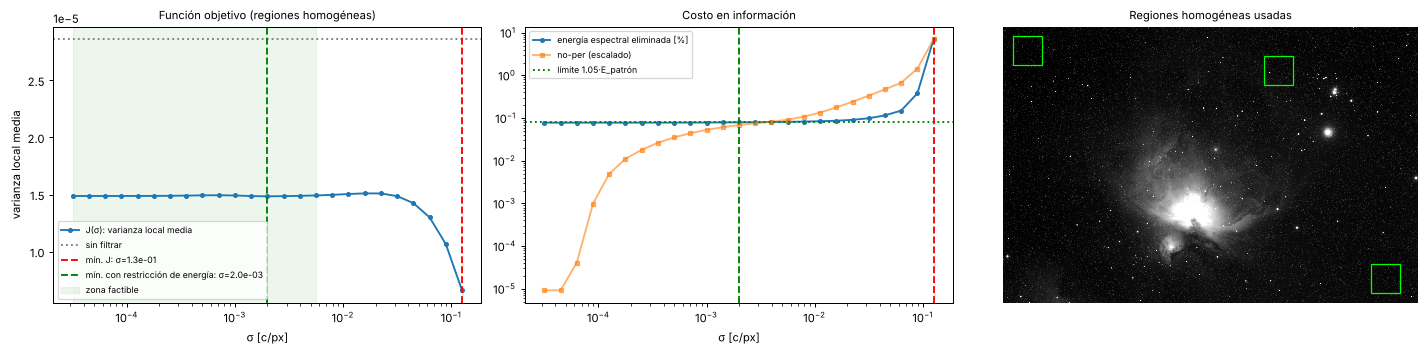

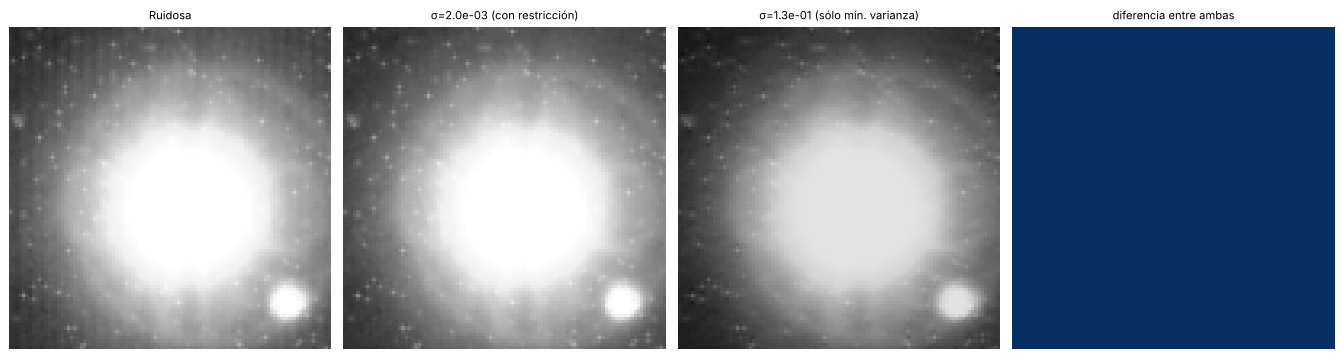

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].semilogx(SIGMAS, J, "o-", ms=3, label="J(σ): varianza local media")
ax[0].axhline(v0, color="gray", ls=":", label="sin filtrar")
ax[0].axvline(s_min, color="r", ls="--", label=f"mín. J: σ={s_min:.1e}")
ax[0].axvline(s_res, color="g", ls="--", label=f"mín. con restricción de energía: σ={s_res:.1e}")
ax[0].axvspan(SIGMAS[0], SIGMAS[factible][-1], color="g", alpha=0.07, label="zona factible")
ax[0].set_xlabel("σ [c/px]"); ax[0].set_ylabel("varianza local media"); ax[0].legend(fontsize=7)
ax[0].set_title("Función objetivo (regiones homogéneas)")
ax[1].loglog(SIGMAS, 100 * Equit, "o-", ms=3, label="energía espectral eliminada [%]")
ax[1].loglog(SIGMAS, npers / npers.max() * 100 * Equit.max(), "s-", ms=3, alpha=0.6, label="no-per (escalado)")
ax[1].axhline(105 * E_ref, color="g", ls=":", label="límite 1.05·E_patrón")
ax[1].axvline(s_min, color="r", ls="--"); ax[1].axvline(s_res, color="g", ls="--")
ax[1].set_xlabel("σ [c/px]"); ax[1].legend(fontsize=7); ax[1].set_title("Costo en información")
for r in REGIONES_HOMOG:
    pass
ax[2].imshow(estirar(I, LO, HI)[::4, ::4], cmap="gray")
for r, mk in zip(REGIONES_HOMOG, MASCARAS):
    ax[2].add_patch(plt.Rectangle((r[1] / 4, r[0] / 4), r[2] / 4, r[2] / 4, fill=False, ec="lime"))
ax[2].set_title("Regiones homogéneas usadas"); ax[2].axis("off")
plt.tight_layout(); guardar(fig, "p1_bonus")
g_sel, _, _ = evaluar(s_res); g_min, _, _ = evaluar(s_min)
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, img, ttl in zip(ax, [I, g_sel, g_min, g_min - g_sel],
                       ["Ruidosa", f"σ={s_res:.1e} (con restricción)", f"σ={s_min:.1e} (sólo mín. varianza)", "diferencia entre ambas"]):
    if ttl.startswith("dif"):
        a.imshow(rec(img, REC_ESTRELLA), cmap="RdBu_r", vmin=-ESC_DIF, vmax=ESC_DIF)
    else:
        a.imshow(estirar(rec(img, REC_ESTRELLA), LO, HI), cmap="gray", vmin=0, vmax=1)
    a.set_title(ttl); a.axis("off")
plt.tight_layout(); guardar(fig, "p1_bonus_resultado")
del F_ext

---
# Pregunta 2 — Deconvolución de Wiener y Tikhonov iterativo

## 2.0 Datos, modelo de degradación y convención de borde

* $x$: `cameraman.jpg` convertida a gris y normalizada a $[0, 1]$ ($256\times256$).
* $h$: `psf.png` ($15\times15$) normalizada a suma 1 (conserva el brillo medio: $H(0,0)=1$).
* **Convención de borde: convolución circular (periódica)** en todas las comparaciones. El
  operador $H$ se aplica como producto en frecuencia y $H^T$ como producto por $H^*$, de modo que
  ambos operadores son exactamente adjuntos y diagonales en la base de Fourier. Esta elección
  hace que la solución cerrada (Wiener/Tikhonov) y la iterativa resuelvan *exactamente* el mismo
  problema, que es lo que se pide comparar en el ítem 4.
* Observación: $y = h \circledast x + n$, con $n \sim \mathcal{N}(0, \sigma_n^2)$, semilla fija.

x: (256, 256), rango [0.000, 1.000]
h: (15, 15), suma = 1.000000, máximo en (np.int64(7), np.int64(7))
centroide de h = (7.002, 7.006)  -> origen elegido: (7, 7)
asimetría ||h - rot180(h)||_1 / ||h||_1 = 0.003  (h no es exactamente simétrica)


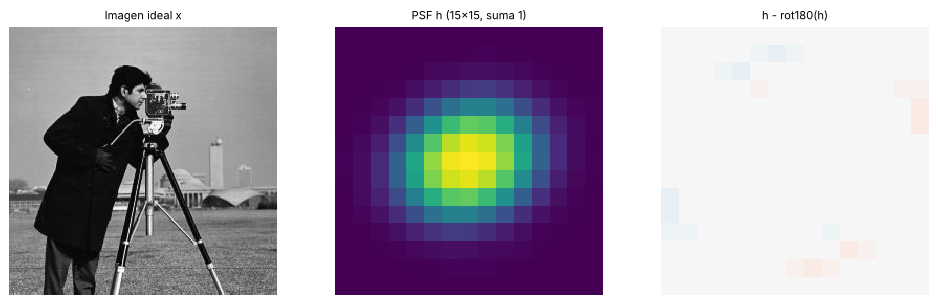

In [23]:
x = np.asarray(Image.open(DATA / "cameraman.jpg").convert("L"), dtype=np.float64) / 255.0
h = np.asarray(Image.open(DATA / "psf.png").convert("L"), dtype=np.float64)
h = h / h.sum()
print(f"x: {x.shape}, rango [{x.min():.3f}, {x.max():.3f}]")
print(f"h: {h.shape}, suma = {h.sum():.6f}, máximo en {np.unravel_index(h.argmax(), h.shape)}")
yy_, xx_ = np.mgrid[:h.shape[0], :h.shape[1]]
print(f"centroide de h = ({(yy_ * h).sum():.3f}, {(xx_ * h).sum():.3f})  -> origen elegido: ({h.shape[0]//2}, {h.shape[1]//2})")
asim = np.abs(h - h[::-1, ::-1]).sum() / h.sum()
print(f"asimetría ||h - rot180(h)||_1 / ||h||_1 = {asim:.3f}  (h no es exactamente simétrica)")

fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
ax[0].imshow(x, cmap="gray", vmin=0, vmax=1); ax[0].set_title("Imagen ideal x")
ax[1].imshow(h, cmap="viridis"); ax[1].set_title("PSF h (15x15, suma 1)")
ax[2].imshow(h - h[::-1, ::-1], cmap="RdBu_r", vmin=-h.max() / 10, vmax=h.max() / 10); ax[2].set_title("h - rot180(h)")
for a in ax: a.axis("off")
plt.tight_layout(); guardar(fig, "p2_datos")

## Construcción de $H(u,v)$ y operadores $H$, $H^T$

In [24]:
def psf_a_otf(h, forma):
    """PSF espacial -> respuesta en frecuencia H(u,v) del tamaño de la imagen.
    1) se inserta h en una matriz de ceros del tamaño de la imagen (esquina superior izquierda);
    2) se desplaza circularmente para que el CENTRO de h (fila 7, col 7) quede en el píxel (0,0);
    3) FFT 2D.  Así la convolución no introduce traslación."""
    P = np.zeros(forma)
    P[:h.shape[0], :h.shape[1]] = h
    cy, cx = h.shape[0] // 2, h.shape[1] // 2
    P = np.roll(P, (-cy, -cx), axis=(0, 1))
    return sfft.fft2(P)


def op_H(x, Hf):
    """H x : convolución circular con la PSF."""
    return sfft.ifft2(Hf * sfft.fft2(x)).real


def op_Ht(z, Hf):
    """H^T z : correlación circular con la PSF = convolución con h rotada 180° = producto por conj(H)."""
    return sfft.ifft2(np.conj(Hf) * sfft.fft2(z)).real


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


Hf = psf_a_otf(h, x.shape)
print(f"H(0,0) = {Hf[0, 0].real:.6f};  max|H| = {np.abs(Hf).max():.6f};  min|H| = {np.abs(Hf).min():.3e}")
print(f"Parte imaginaria relativa de H: {np.abs(Hf.imag).max() / np.abs(Hf).max():.3e} (≠0 porque h no es simétrica)")

# Prueba de adjunción <Hu, v> = <u, H^T v>
rng = np.random.default_rng(0)
u_, v_ = rng.standard_normal(x.shape), rng.standard_normal(x.shape)
lhs, rhs = np.sum(op_H(u_, Hf) * v_), np.sum(u_ * op_Ht(v_, Hf))
print(f"Prueba de adjunción: <Hu,v> = {lhs:.10f},  <u,H^T v> = {rhs:.10f},  dif. relativa = {abs(lhs-rhs)/abs(lhs):.1e}")
# Si se usara H en lugar de H^T (ignorar la asimetría):
rhs_mal = np.sum(u_ * op_H(v_, Hf))
print(f"Usando H como si fuera H^T:  <u,H v> = {rhs_mal:.6f}  -> dif. relativa = {abs(lhs-rhs_mal)/abs(lhs):.1e}")
# Comparación con convolución espacial directa (verificación independiente del centrado)
from scipy.ndimage import convolve as conv_esp
ref = conv_esp(x, h, mode="wrap")
print(f"Diferencia máx. entre op_H y convolución espacial circular directa: {np.abs(op_H(x, Hf) - ref).max():.2e}")

H(0,0) = 1.000000;  max|H| = 1.000000;  min|H| = 1.997e-06
Parte imaginaria relativa de H: 1.277e-03 (≠0 porque h no es simétrica)
Prueba de adjunción: <Hu,v> = -49.8080369037,  <u,H^T v> = -49.8080369037,  dif. relativa = 0.0e+00
Usando H como si fuera H^T:  <u,H v> = -49.675272  -> dif. relativa = 2.7e-03
Diferencia máx. entre op_H y convolución espacial circular directa: 1.22e-15


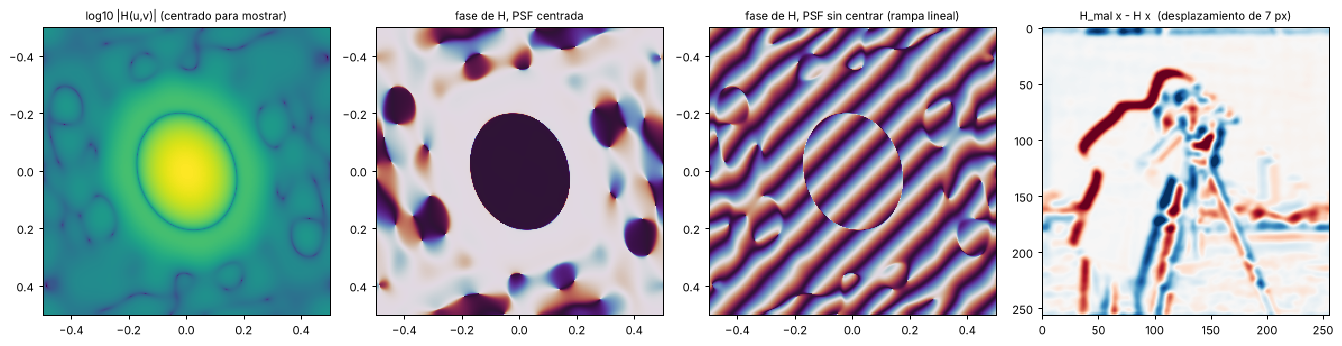

In [25]:
# ¿Qué pasa si el centrado se hace mal? (h en la esquina sin desplazar)
P_mal = np.zeros(x.shape); P_mal[:15, :15] = h
H_mal = sfft.fft2(P_mal)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
ax[0].imshow(np.fft.fftshift(np.log10(np.abs(Hf) + 1e-12)), cmap="viridis", extent=(-0.5, 0.5, 0.5, -0.5))
ax[0].set_title("log10 |H(u,v)| (centrado para mostrar)")
ax[1].imshow(np.fft.fftshift(np.angle(Hf)), cmap="twilight", extent=(-0.5, 0.5, 0.5, -0.5)); ax[1].set_title("fase de H, PSF centrada")
ax[2].imshow(np.fft.fftshift(np.angle(H_mal)), cmap="twilight", extent=(-0.5, 0.5, 0.5, -0.5)); ax[2].set_title("fase de H, PSF sin centrar (rampa lineal)")
y_mal = op_H(x, H_mal)
ax[3].imshow(y_mal - op_H(x, Hf), cmap="RdBu_r", vmin=-0.5, vmax=0.5)
ax[3].set_title("H_mal x - H x  (desplazamiento de 7 px)")
plt.tight_layout(); guardar(fig, "p2_otf")

## Observaciones degradadas (dos niveles de ruido)

In [26]:
SIGMAS_N = [0.01, 0.05]           # desviación estándar del ruido (imagen en [0,1])
rng = np.random.default_rng(2026)
y_obs = {s: op_H(x, Hf) + s * rng.standard_normal(x.shape) for s in SIGMAS_N}
for s in SIGMAS_N:
    print(f"σ_n = {s}:  RMSE(y, x) = {rmse(y_obs[s], x):.4f}   SNR(Hx) = {10*np.log10(np.var(op_H(x,Hf))/s**2):.1f} dB")

σ_n = 0.01:  RMSE(y, x) = 0.0807   SNR(Hx) = 26.9 dB
σ_n = 0.05:  RMSE(y, x) = 0.0942   SNR(Hx) = 12.9 dB


## Parte A — Filtro de Wiener simplificado
$\hat X = \dfrac{H^*\,Y}{|H|^2 + K}$

In [27]:
def wiener(y, Hf, K):
    Y = sfft.fft2(y)
    return sfft.ifft2(np.conj(Hf) * Y / (np.abs(Hf) ** 2 + K)).real


KS = np.logspace(-7, 0, 71)
curvas_K, K_opt = {}, {}
for s in SIGMAS_N:
    curvas_K[s] = np.array([rmse(wiener(y_obs[s], Hf, K), x) for K in KS])
    K_opt[s] = KS[np.argmin(curvas_K[s])]
    print(f"σ_n = {s}:  K óptimo = {K_opt[s]:.3e}   RMSE mínimo = {curvas_K[s].min():.4f}   "
          f"(RMSE con K=1e-7: {curvas_K[s][0]:.3f})")
print(f"Filtro inverso puro (K=0), σ_n=0.01: RMSE = {rmse(wiener(y_obs[0.01], Hf, 0.0), x):.3e}")

σ_n = 0.01:  K óptimo = 5.012e-03   RMSE mínimo = 0.0657   (RMSE con K=1e-7: 9.604)
σ_n = 0.05:  K óptimo = 3.162e-02   RMSE mínimo = 0.0783   (RMSE con K=1e-7: 47.877)
Filtro inverso puro (K=0), σ_n=0.01: RMSE = 3.969e+01


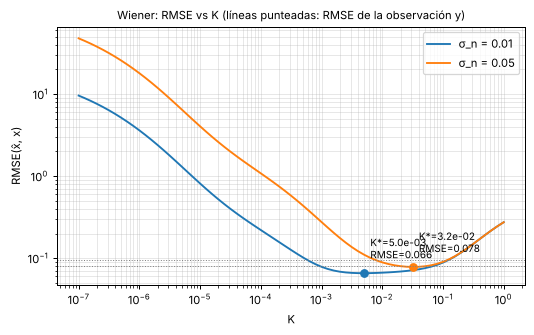

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3.8))
for s in SIGMAS_N:
    ax.loglog(KS, curvas_K[s], label=f"σ_n = {s}")
    ax.plot(K_opt[s], curvas_K[s].min(), "o", color=ax.lines[-1].get_color())
    ax.annotate(f"K*={K_opt[s]:.1e}\nRMSE={curvas_K[s].min():.3f}", (K_opt[s], curvas_K[s].min()),
                textcoords="offset points", xytext=(5, 12), fontsize=8)
for s in SIGMAS_N:
    ax.axhline(rmse(y_obs[s], x), ls=":", lw=0.8, color="gray")
ax.set_xlabel("K"); ax.set_ylabel("RMSE(x̂, x)"); ax.grid(alpha=0.3, which="both"); ax.legend()
ax.set_title("Wiener: RMSE vs K (líneas punteadas: RMSE de la observación y)")
plt.tight_layout(); guardar(fig, "p2_wiener_rmse_K")

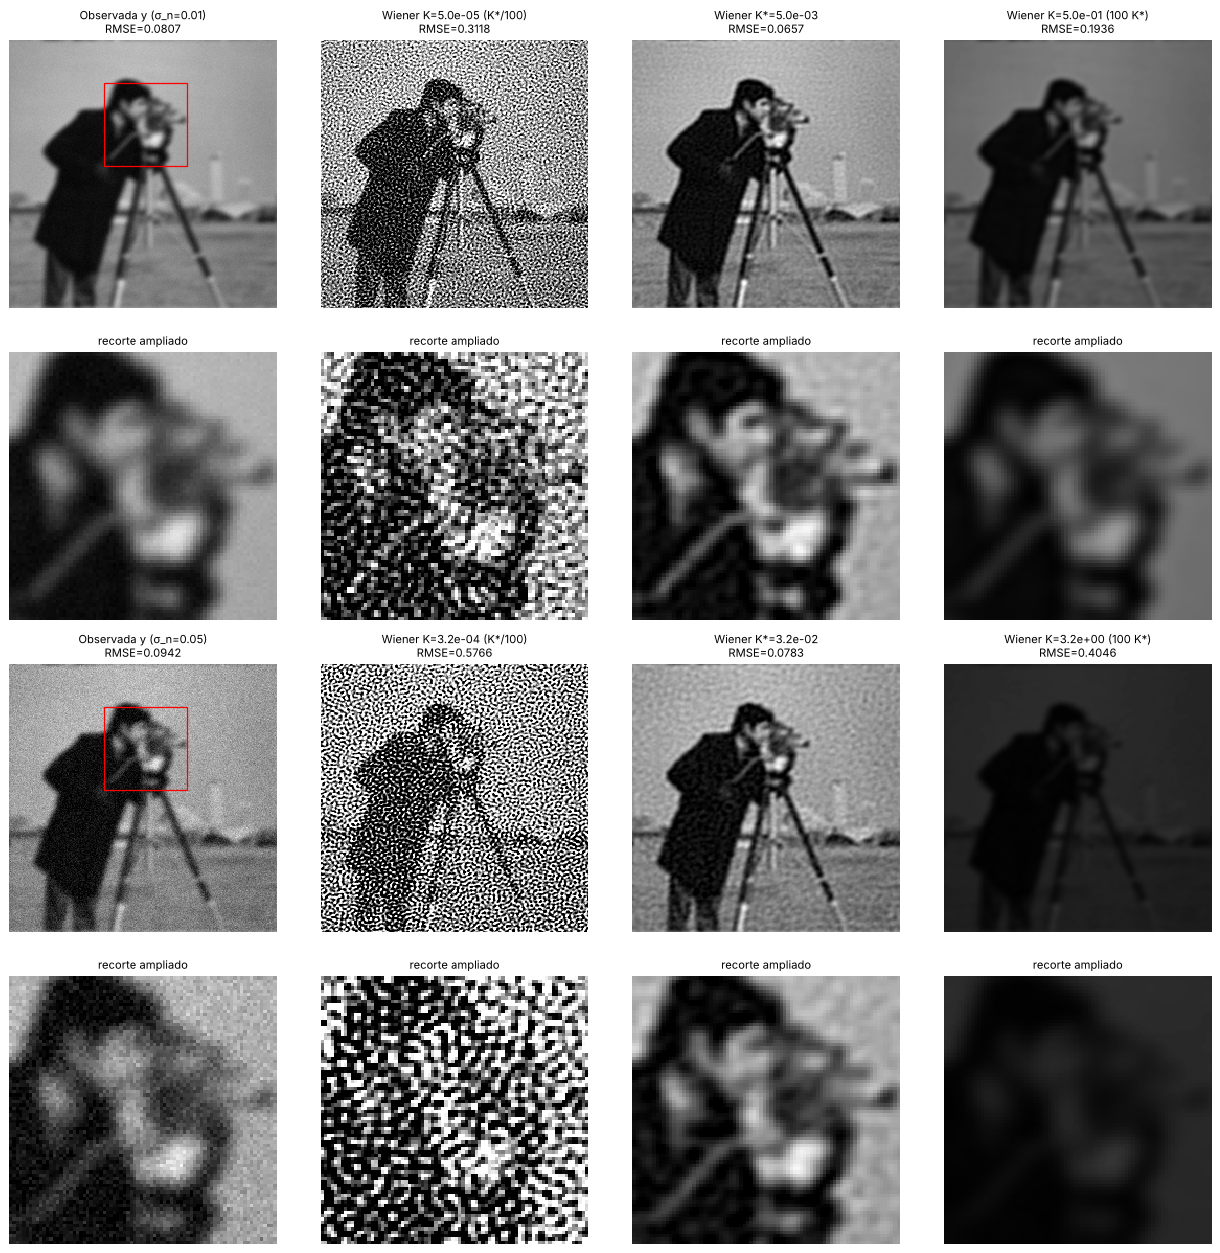

In [29]:
REC2 = (40, 90, 80)    # recorte ampliado: cabeza y cámara
def rec2(img):
    f, c, s = REC2
    return img[f:f + s, c:c + s]

fig, ax = plt.subplots(4, 4, figsize=(14, 14))
for i, s in enumerate(SIGMAS_N):
    Kb = K_opt[s]
    casos = [(y_obs[s], f"Observada y (σ_n={s})\nRMSE={rmse(y_obs[s], x):.4f}"),
             (wiener(y_obs[s], Hf, Kb / 100), f"Wiener K={Kb/100:.1e} (K*/100)\nRMSE={rmse(wiener(y_obs[s], Hf, Kb/100), x):.4f}"),
             (wiener(y_obs[s], Hf, Kb), f"Wiener K*={Kb:.1e}\nRMSE={rmse(wiener(y_obs[s], Hf, Kb), x):.4f}"),
             (wiener(y_obs[s], Hf, Kb * 100), f"Wiener K={Kb*100:.1e} (100 K*)\nRMSE={rmse(wiener(y_obs[s], Hf, Kb*100), x):.4f}")]
    for j, (img, t) in enumerate(casos):
        ax[2 * i, j].imshow(img, cmap="gray", vmin=0, vmax=1); ax[2 * i, j].set_title(t)
        ax[2 * i + 1, j].imshow(rec2(img), cmap="gray", vmin=0, vmax=1); ax[2 * i + 1, j].set_title("recorte ampliado")
        if j == 0:
            ax[2 * i, j].add_patch(plt.Rectangle((REC2[1], REC2[0]), REC2[2], REC2[2], fill=False, ec="r"))
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); guardar(fig, "p2_wiener_recon")

### PSF ligeramente incorrecta
Se reconstruye la observación con $\sigma_n = 0.01$ usando dos PSF perturbadas (renormalizadas
a suma 1):
1. **rotada 20°** respecto de su centro (interpolación bilineal);
2. **ensanchada 15 %** (reescalada por 1.15 e insertada en una grilla de 19x19 centrada);
3. **desplazada 1 px** en diagonal (error de centrado/registro de la PSF).

PSF rotada 20°      : RMSE con K*(PSF correcta)=5.0e-03: 0.0662;  K óptimo propio = 5.0e-03 -> RMSE 0.0662
PSF ensanchada 15 % : RMSE con K*(PSF correcta)=5.0e-03: 0.0708;  K óptimo propio = 1.0e-02 -> RMSE 0.0700
PSF desplazada 1 px : RMSE con K*(PSF correcta)=5.0e-03: 0.0844;  K óptimo propio = 1.3e-02 -> RMSE 0.0834
PSF correcta          : RMSE con K* = 0.0657


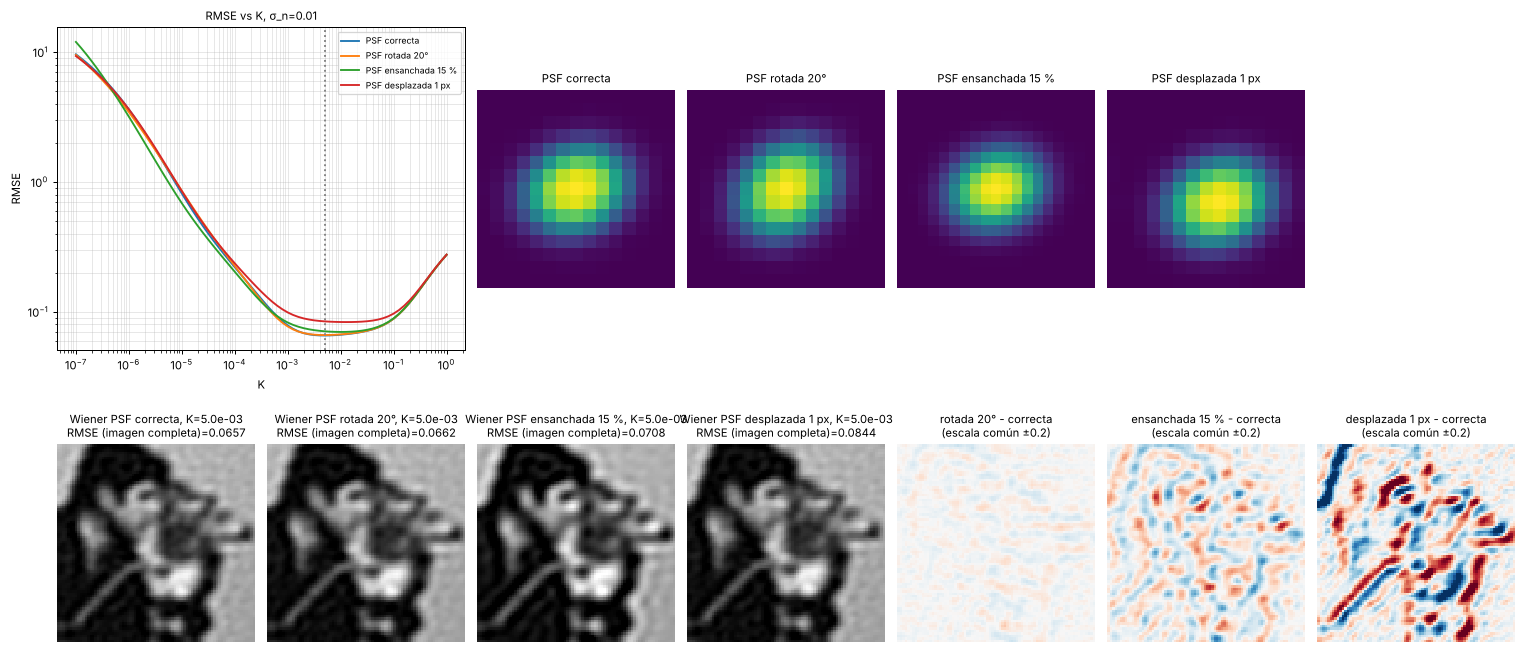

In [30]:
def psf_rotada(h, ang):
    hr = np.clip(rotate(h, ang, reshape=False, order=1), 0, None)
    return hr / hr.sum()

def psf_escalada(h, f, tam=19):
    hz = np.clip(zoom(h, f, order=1), 0, None)
    out = np.zeros((tam, tam))
    oy, ox = (tam - hz.shape[0]) // 2, (tam - hz.shape[1]) // 2
    out[oy:oy + hz.shape[0], ox:ox + hz.shape[1]] = hz
    return out / out.sum()

s_pert = 0.01
psfs_pert = {"rotada 20°": psf_rotada(h, 20), "ensanchada 15 %": psf_escalada(h, 1.15),
             "desplazada 1 px": np.roll(h, (1, 1), axis=(0, 1))}
curvas_pert = {}
for nom, hp in psfs_pert.items():
    Hp = psf_a_otf(hp, x.shape)
    curvas_pert[nom] = (Hp, np.array([rmse(wiener(y_obs[s_pert], Hp, K), x) for K in KS]))
    Kp = KS[np.argmin(curvas_pert[nom][1])]
    print(f"PSF {nom:16s}: RMSE con K*(PSF correcta)={K_opt[s_pert]:.1e}: "
          f"{rmse(wiener(y_obs[s_pert], Hp, K_opt[s_pert]), x):.4f};  K óptimo propio = {Kp:.1e} -> RMSE {curvas_pert[nom][1].min():.4f}")
print(f"PSF correcta          : RMSE con K* = {curvas_K[s_pert].min():.4f}")

fig = plt.figure(figsize=(17, 8))
gs = fig.add_gridspec(2, 7)
a = fig.add_subplot(gs[0, 0:2])
a.loglog(KS, curvas_K[s_pert], label="PSF correcta")
for nom in psfs_pert:
    a.loglog(KS, curvas_pert[nom][1], label=f"PSF {nom}")
a.axvline(K_opt[s_pert], color="gray", ls=":"); a.legend(fontsize=7); a.set_xlabel("K"); a.set_ylabel("RMSE")
a.set_title(f"RMSE vs K, σ_n={s_pert}"); a.grid(alpha=0.3, which="both")
for j, (nom, hp) in enumerate([("correcta", h)] + list(psfs_pert.items())):
    a = fig.add_subplot(gs[0, j + 2]); a.imshow(hp, cmap="viridis"); a.set_title(f"PSF {nom}"); a.axis("off")
recs = [("correcta", wiener(y_obs[s_pert], Hf, K_opt[s_pert]))] + \
       [(nom, wiener(y_obs[s_pert], curvas_pert[nom][0], K_opt[s_pert])) for nom in psfs_pert]
for j, (nom, img) in enumerate(recs):
    a = fig.add_subplot(gs[1, j])
    a.imshow(rec2(img), cmap="gray", vmin=0, vmax=1)
    a.set_title(f"Wiener PSF {nom}, K={K_opt[s_pert]:.1e}\nRMSE (imagen completa)={rmse(img, x):.4f}"); a.axis("off")
for j, nom in enumerate(psfs_pert, start=1):
    a = fig.add_subplot(gs[1, 3 + j])
    a.imshow(rec2(recs[j][1] - recs[0][1]), cmap="RdBu_r", vmin=-0.2, vmax=0.2)
    a.set_title(f"{nom} - correcta\n(escala común ±0.2)"); a.axis("off")
plt.tight_layout(); guardar(fig, "p2_psf_incorrecta")

## Parte B — Tikhonov de orden cero por descenso de gradiente

$\min_x \; J(x) = \tfrac12\|Hx-y\|_2^2 + \tfrac{\lambda}{2}\|x\|_2^2$,
$\quad \nabla J(x) = \underbrace{H^T(Hx-y)}_{\text{fidelidad}} + \underbrace{\lambda x}_{\text{regularización}}$,
$\quad x^{k+1} = x^k - \tau\,\nabla J(x^k)$.

**Criterio de detención**: cambio relativo del iterado
$\delta_k = \|x^{k+1}-x^k\|_2 / \|x^k\|_2 < \text{tol}$ (comparación entre iteraciones consecutivas
$k$ y $k+1$), o bien alcanzar `max_iter`. Además se detiene si el costo se vuelve no finito o
crece por sobre $10^6\,J(x^0)$ (divergencia).

In [31]:
def tikhonov_gd(y, Hf, lam, tau, max_iter=2000, tol=1e-5, x0=None, x_ref=None):
    """Descenso de gradiente para Tikhonov de orden cero. Devuelve (x_final, historia)."""
    xk = y.copy() if x0 is None else x0.copy()
    hist = {"costo": [], "rmse": [], "delta": [], "motivo": "max_iter", "iters": 0,
            "mejor_rmse": np.inf, "mejor_iter": 0, "x_mejor": xk.copy()}
    r = op_H(xk, Hf) - y
    J0 = 0.5 * np.sum(r ** 2) + 0.5 * lam * np.sum(xk ** 2)
    for k in range(max_iter):
        costo = 0.5 * np.sum(r ** 2) + 0.5 * lam * np.sum(xk ** 2)      # J(x^k)
        hist["costo"].append(costo)
        if x_ref is not None:
            e = rmse(xk, x_ref); hist["rmse"].append(e)
            if e < hist["mejor_rmse"]:
                hist["mejor_rmse"], hist["mejor_iter"], hist["x_mejor"] = e, k, xk.copy()
        if not np.isfinite(costo) or costo > 1e6 * J0:
            hist["motivo"] = "divergencia"; break
        grad_fid = op_Ht(r, Hf)          # H^T (H x^k - y)   -> término de fidelidad
        grad_reg = lam * xk              # lambda x^k        -> término de regularización
        x_new = xk - tau * (grad_fid + grad_reg)
        delta = np.linalg.norm(x_new - xk) / max(np.linalg.norm(xk), 1e-12)
        hist["delta"].append(delta)
        xk = x_new
        r = op_H(xk, Hf) - y
        hist["iters"] = k + 1
        if delta < tol:                  # <-- decisión de detención (iteraciones k y k+1)
            hist["motivo"] = f"delta<{tol:g}"; break
    return xk, hist


def tikhonov_cerrado(y, Hf, lam):
    """Solución cerrada (H^T H + λI)^{-1} H^T y, diagonal en Fourier con borde circular."""
    return wiener(y, Hf, lam)

print("Cota de estabilidad: τ < 2/(max|H|^2 + λ) =", 2 / (np.abs(Hf).max() ** 2), "(para λ→0)")

Cota de estabilidad: τ < 2/(max|H|^2 + λ) = 2.0 (para λ→0)


### Exploración de λ y τ (σ_n = 0.01)
Se usa $x^0 = y$, `max_iter` = 3000 y **sin** criterio de detención (tol = 0) para ver la
evolución completa. $\lambda \in \{0,\ K^*/10,\ K^*,\ 10K^*,\ 100K^*\}$ y $\tau \in \{0.5,\ 1.9\}$,
más $\tau = 2.05$ para mostrar inestabilidad.

In [32]:
s_t = 0.01
Kt = K_opt[s_t]
LAMS = [0.0, Kt / 10, Kt, 10 * Kt, 100 * Kt]
TAUS = [0.5, 1.9]
runs = {}
t0 = time.time()
for tau in TAUS:
    for lam in LAMS:
        _, hst = tikhonov_gd(y_obs[s_t], Hf, lam, tau, max_iter=3000, tol=0.0, x_ref=x)
        runs[(lam, tau)] = hst
_, hst = tikhonov_gd(y_obs[s_t], Hf, Kt, 2.05, max_iter=3000, tol=0.0, x_ref=x)
runs[(Kt, 2.05)] = hst
print(f"tiempo total: {time.time()-t0:.1f} s")
print(f"{'λ':>10s} {'τ':>5s} | {'iters':>5s} {'motivo':>12s} | {'RMSE final':>10s} {'mejor RMSE':>10s} {'en iter':>7s} | {'J final':>10s}")
for (lam, tau), hst in runs.items():
    print(f"{lam:10.2e} {tau:5.2f} | {hst['iters']:5d} {hst['motivo']:>12s} | {hst['rmse'][-1]:10.4f} "
          f"{hst['mejor_rmse']:10.4f} {hst['mejor_iter']:7d} | {hst['costo'][-1]:10.4e}")

tiempo total: 70.7 s
         λ     τ | iters       motivo | RMSE final mejor RMSE en iter |    J final
  0.00e+00  0.50 |  3000     max_iter |     0.0963     0.0658     374 | 2.7300e+00
  5.01e-04  0.50 |  3000     max_iter |     0.0819     0.0657     404 | 7.3253e+00
  5.01e-03  0.50 |  3000     max_iter |     0.0657     0.0656     727 | 4.7460e+01
  5.01e-02  0.50 |  3000     max_iter |     0.0756     0.0756    1679 | 4.2628e+02
  5.01e-01  0.50 |  3000     max_iter |     0.1936     0.0807       0 | 2.9357e+03
  0.00e+00  1.90 |  3000     max_iter |     0.1980     0.0658      98 | 2.4847e+00
  5.01e-04  1.90 |  3000     max_iter |     0.1003     0.0657     106 | 7.3046e+00
  5.01e-03  1.90 |  3000     max_iter |     0.0657     0.0656     190 | 4.7460e+01
  5.01e-02  1.90 |  3000     max_iter |     0.0756     0.0718      26 | 4.2628e+02
  5.01e-01  1.90 |    13  divergencia |   503.9109     0.0807       0 | 1.2475e+10
  5.01e-03  2.05 |   168  divergencia |    43.4543     0.0680     

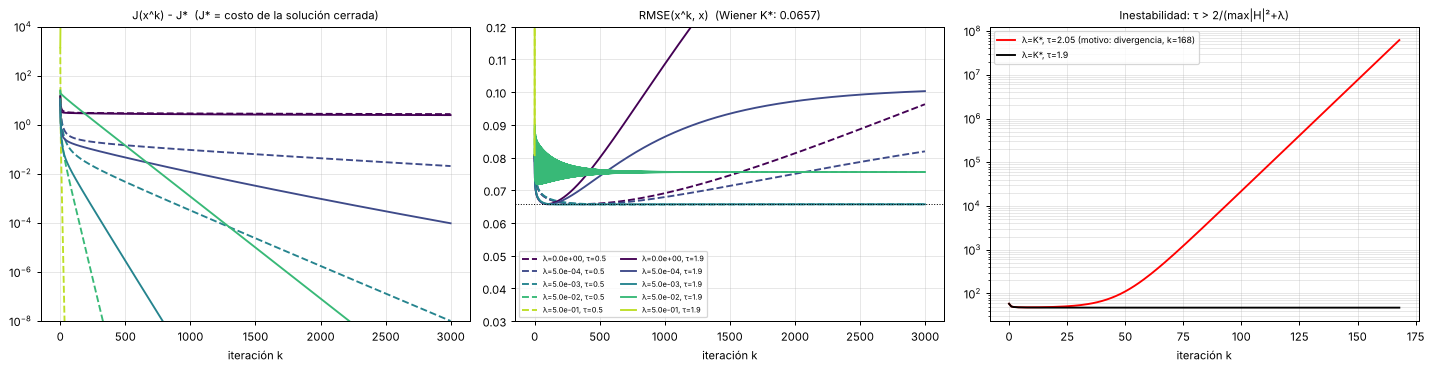

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
estilos = {0.5: "--", 1.9: "-"}
colores = dict(zip(LAMS, plt.cm.viridis(np.linspace(0, 0.9, len(LAMS)))))
for (lam, tau), hst in runs.items():
    if tau == 2.05:
        continue
    lab = f"λ={lam:.1e}, τ={tau}"
    xs_ = tikhonov_cerrado(y_obs[s_t], Hf, lam)
    J_est = 0.5 * np.sum((op_H(xs_, Hf) - y_obs[s_t]) ** 2) + 0.5 * lam * np.sum(xs_ ** 2)
    ax[0].semilogy(np.maximum(np.array(hst["costo"]) - J_est, 1e-12), estilos[tau], color=colores[lam], label=lab)
    ax[1].plot(hst["rmse"], estilos[tau], color=colores[lam], label=lab)
ax[0].set_title("J(x^k) - J*  (J* = costo de la solución cerrada)"); ax[0].set_xlabel("iteración k")
ax[0].set_ylim(1e-8, 1e4)
ax[1].set_title(f"RMSE(x^k, x)  (Wiener K*: {curvas_K[s_t].min():.4f})"); ax[1].set_xlabel("iteración k")
ax[1].axhline(curvas_K[s_t].min(), color="k", ls=":", lw=0.8)
ax[1].set_ylim(0.03, 0.12); ax[1].legend(fontsize=6, ncol=2)
hst = runs[(Kt, 2.05)]
ax[2].semilogy(hst["costo"], "r-", label=f"λ=K*, τ=2.05 (motivo: {hst['motivo']}, k={hst['iters']})")
ax[2].semilogy(runs[(Kt, 1.9)]["costo"][:len(hst['costo'])], "k-", label="λ=K*, τ=1.9")
ax[2].set_title("Inestabilidad: τ > 2/(max|H|²+λ)"); ax[2].set_xlabel("iteración k"); ax[2].legend(fontsize=7)
for a in ax: a.grid(alpha=0.3, which="both")
plt.tight_layout(); guardar(fig, "p2_tikhonov_curvas")

### Efecto del criterio de detención
Para λ = 0 (Landweber) y λ = K*, con τ = 1.9, se varía la tolerancia del cambio relativo.

In [34]:
TOLS = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
print(f"{'λ':>9s} {'tol':>7s} | {'iters':>6s} {'motivo':>12s} | {'RMSE al detener':>15s} | {'mejor RMSE (oráculo)':>20s}")
tabla_tol = []
for lam in [0.0, Kt]:
    for tol in TOLS:
        xf, hst = tikhonov_gd(y_obs[s_t], Hf, lam, 1.9, max_iter=20000, tol=tol, x_ref=x)
        tabla_tol.append((lam, tol, hst["iters"], rmse(xf, x)))
        print(f"{lam:9.2e} {tol:7.0e} | {hst['iters']:6d} {hst['motivo']:>12s} | {rmse(xf, x):15.4f} | "
              f"{hst['mejor_rmse']:.4f} (k={hst['mejor_iter']})")

        λ     tol |  iters       motivo | RMSE al detener | mejor RMSE (oráculo)
 0.00e+00   1e-02 |      4   delta<0.01 |          0.0718 | 0.0726 (k=3)
 0.00e+00   1e-03 |     21  delta<0.001 |          0.0679 | 0.0680 (k=20)
 0.00e+00   1e-04 |   1819 delta<0.0001 |          0.1513 | 0.0658 (k=98)
 0.00e+00   1e-05 |  20000     max_iter |          0.5009 | 0.0658 (k=98)
 0.00e+00   1e-06 |  20000     max_iter |          0.5009 | 0.0658 (k=98)
 5.01e-03   1e-02 |      4   delta<0.01 |          0.0719 | 0.0728 (k=3)
 5.01e-03   1e-03 |     27  delta<0.001 |          0.0676 | 0.0676 (k=26)
 5.01e-03   1e-04 |    136 delta<0.0001 |          0.0657 | 0.0657 (k=135)
 5.01e-03   1e-05 |    360  delta<1e-05 |          0.0657 | 0.0656 (k=190)
 5.01e-03   1e-06 |    592  delta<1e-06 |          0.0657 | 0.0656 (k=190)


### Comparación con la solución cerrada para λ = K* y λ = 0

In [35]:
resumen = []
mejores = {}
for s in SIGMAS_N:
    Ks = K_opt[s]
    x_w = wiener(y_obs[s], Hf, Ks)
    # λ = K: iterar hasta convergencia fina
    t0 = time.time()
    x_it, hK = tikhonov_gd(y_obs[s], Hf, Ks, 1.9, max_iter=40000, tol=1e-9, x_ref=x)
    t_it = time.time() - t0
    # predicción teórica del error por frecuencia: (1 - τ(|H|^2+λ))^k
    fac = np.abs(1 - 1.9 * (np.abs(Hf) ** 2 + Ks)).max()
    # λ = 0: solución cerrada = filtro inverso; iterativa = Landweber con detención temprana óptima
    x_inv = tikhonov_cerrado(y_obs[s], Hf, 0.0)
    _, h0 = tikhonov_gd(y_obs[s], Hf, 0.0, 1.9, max_iter=3000, tol=0.0, x_ref=x)
    mejores[s] = dict(x_w=x_w, x_it=x_it, x_land=h0["x_mejor"], k_land=h0["mejor_iter"])
    resumen.append((s, Ks, rmse(x_w, x), rmse(x_it, x), rmse(hK["x_mejor"], x), hK["iters"],
                    np.linalg.norm(x_it - x_w) / np.linalg.norm(x_w), np.abs(x_it - x_w).max(), fac, t_it,
                    rmse(x_inv, x), h0["mejor_rmse"], h0["mejor_iter"]))
for r in resumen:
    print(f"σ_n={r[0]}:  λ=K*={r[1]:.2e}")
    print(f"   Wiener/Tikhonov cerrado: RMSE = {r[2]:.6f}")
    print(f"   Tikhonov GD (τ=1.9, tol=1e-9): RMSE final = {r[3]:.6f} (mejor iterado {r[4]:.6f}), {r[5]} iteraciones, {r[9]:.1f} s")
    print(f"   ||x_GD - x_W|| / ||x_W|| = {r[6]:.2e},  max|x_GD - x_W| = {r[7]:.2e};  factor de contracción más lento = {r[8]:.6f}")
    print(f"   λ=0: inversa cerrada Y/H: RMSE = {r[10]:.3e};  Landweber con detención óptima: RMSE = {r[11]:.4f} (k = {r[12]})")

σ_n=0.01:  λ=K*=5.01e-03
   Wiener/Tikhonov cerrado: RMSE = 0.065696
   Tikhonov GD (τ=1.9, tol=1e-9): RMSE final = 0.065696 (mejor iterado 0.065615), 1297 iteraciones, 3.5 s
   ||x_GD - x_W|| / ||x_W|| = 1.01e-07,  max|x_GD - x_W| = 2.30e-07;  factor de contracción más lento = 0.990477
   λ=0: inversa cerrada Y/H: RMSE = 3.969e+01;  Landweber con detención óptima: RMSE = 0.0658 (k = 98)
σ_n=0.05:  λ=K*=3.16e-02
   Wiener/Tikhonov cerrado: RMSE = 0.078271
   Tikhonov GD (τ=1.9, tol=1e-9): RMSE final = 0.078271 (mejor iterado 0.077281), 439 iteraciones, 1.1 s
   ||x_GD - x_W|| / ||x_W|| = 4.84e-10,  max|x_GD - x_W| = 2.58e-10;  factor de contracción más lento = 0.960083
   λ=0: inversa cerrada Y/H: RMSE = 1.703e+02;  Landweber con detención óptima: RMSE = 0.0887 (k = 5)


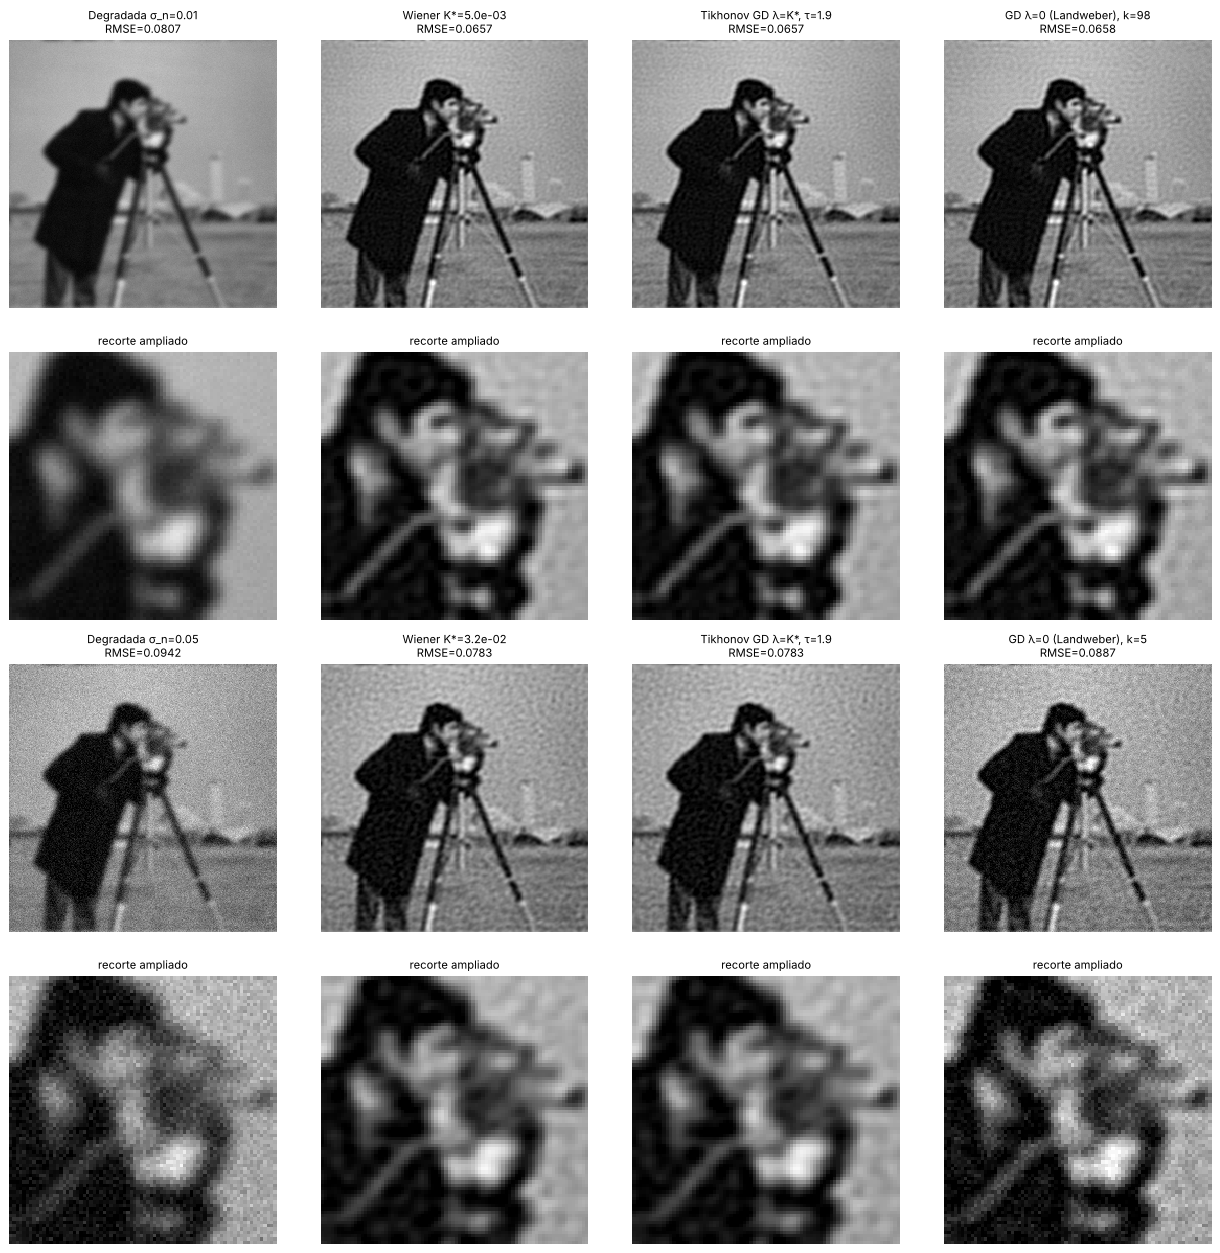

In [36]:
fig, ax = plt.subplots(4, 4, figsize=(14, 14))
for i, s in enumerate(SIGMAS_N):
    mb = mejores[s]
    casos = [(y_obs[s], f"Degradada σ_n={s}\nRMSE={rmse(y_obs[s], x):.4f}"),
             (mb["x_w"], f"Wiener K*={K_opt[s]:.1e}\nRMSE={rmse(mb['x_w'], x):.4f}"),
             (mb["x_it"], f"Tikhonov GD λ=K*, τ=1.9\nRMSE={rmse(mb['x_it'], x):.4f}"),
             (mb["x_land"], f"GD λ=0 (Landweber), k={mb['k_land']}\nRMSE={rmse(mb['x_land'], x):.4f}")]
    for j, (img, t) in enumerate(casos):
        ax[2 * i, j].imshow(img, cmap="gray", vmin=0, vmax=1); ax[2 * i, j].set_title(t)
        ax[2 * i + 1, j].imshow(rec2(img), cmap="gray", vmin=0, vmax=1); ax[2 * i + 1, j].set_title("recorte ampliado")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); guardar(fig, "p2_comparacion_final")

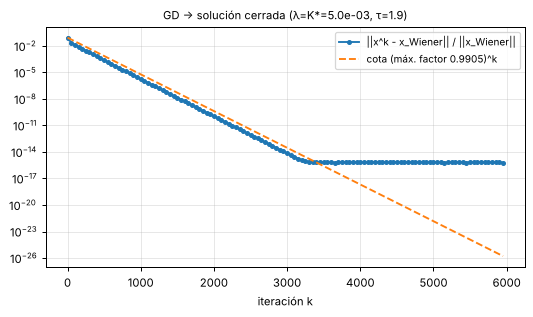

In [37]:
# Convergencia de GD hacia la solución cerrada (λ = K*, σ_n = 0.01)
s = 0.01
x_w = wiener(y_obs[s], Hf, K_opt[s])
dist = []
xk = y_obs[s].copy()
for k in range(6000):
    if k % 50 == 0:
        dist.append((k, np.linalg.norm(xk - x_w) / np.linalg.norm(x_w)))
    xk = xk - 1.9 * (op_Ht(op_H(xk, Hf) - y_obs[s], Hf) + K_opt[s] * xk)
fig, ax = plt.subplots(figsize=(6, 3.6))
ks_, ds_ = zip(*dist)
ax.semilogy(ks_, ds_, "o-", ms=3, label="||x^k - x_Wiener|| / ||x_Wiener||")
fac = np.abs(1 - 1.9 * (np.abs(Hf) ** 2 + K_opt[s])).max()
ax.semilogy(ks_, ds_[0] * fac ** np.array(ks_), "--", label=f"cota (máx. factor {fac:.4f})^k")
ax.set_xlabel("iteración k"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title(f"GD → solución cerrada (λ=K*={K_opt[s]:.1e}, τ=1.9)")
plt.tight_layout(); guardar(fig, "p2_convergencia_cerrada")

## Tabla resumen (Pregunta 2)

In [38]:
print(f"{'σ_n':>5s} | {'K* Wiener':>9s} | {'RMSE y':>7s} | {'RMSE Wiener':>11s} | {'RMSE GD λ=K*':>12s} | {'RMSE GD λ=0 (mejor k)':>22s} | {'RMSE inversa':>12s}")
for r in resumen:
    print(f"{r[0]:5.2f} | {r[1]:9.2e} | {rmse(y_obs[r[0]], x):7.4f} | {r[2]:11.4f} | {r[3]:12.4f} | {r[11]:15.4f} (k={r[12]:4d}) | {r[10]:12.2e}")

  σ_n | K* Wiener |  RMSE y | RMSE Wiener | RMSE GD λ=K* |  RMSE GD λ=0 (mejor k) | RMSE inversa
 0.01 |  5.01e-03 |  0.0807 |      0.0657 |       0.0657 |          0.0658 (k=  98) |     3.97e+01
 0.05 |  3.16e-02 |  0.0942 |      0.0783 |       0.0783 |          0.0887 (k=   5) |     1.70e+02
